# Disney+ Hotstar Subscription Billing & Access Operations Database
## SQL Developer Colab

**Company:** Disney+ Hotstar  
**Industry:** Media & Entertainment / OTT Streaming  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Brand context:** The product title retains the legacy Disney+ Hotstar label for the defined operational data domain; current India platform branding is JioHotstar.  
**Main skills:** Relational design, internal API consumption, SQL reporting, transaction integrity, workflow automation, and safe database changes

Subscription operations needs one SQL-led control environment for billing attempts, lifecycle events, device access, renewals, cancellations, refunds, and access entitlements. The runtime is prebuilt. Complete only the clearly marked SQL Developer workspaces.


## How to Use This Notebook

1. Use **Runtime -> Run all** once.
2. Wait until the setup prints **SETUP COMPLETE**.
3. Scroll to the large **SQL DEVELOPER WORK STARTS HERE** heading.
4. Edit only cells containing **SQL DEVELOPER WORKSPACE**.
5. Rerun each workspace until **Overall status: Passed** is displayed.

### Fast navigation

Search the notebook for:

```text
SQL DEVELOPER WORKSPACE
```

Setup code is grouped under one heading. Mutable API practice records and transaction practice rows are reset so the activities can be rerun safely.


# 1. RUN THIS SETUP ONCE - DO NOT EDIT

## 1.1 Environment and Project Folder

In [ ]:
from __future__ import annotations

import copy
import hashlib
import importlib.util
import json
import math
import os
import random
import re
import shutil
import socket
import sqlite3
import subprocess
import sys
import threading
import urllib.parse
from collections import defaultdict
from datetime import date, datetime, timedelta
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path

import pandas as pd
import requests
from IPython.display import SVG, display

try:
    import graphviz
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "graphviz"])
    import graphviz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

BASE_DIR = Path("/content") if Path("/content").exists() else Path("/mnt/data")
PROJECT_ROOT = BASE_DIR / "disneyplus_hotstar_subscription_ops_runtime"
for name in ["raw_json", "processed", "database", "outputs"]:
    (PROJECT_ROOT / name).mkdir(parents=True, exist_ok=True)

print(f"Project runtime folder ready: {PROJECT_ROOT}")


Project runtime folder ready: /content/disneyplus_hotstar_subscription_ops_runtime


## 1.2 Dataset

The setup creates a deterministic operational Dataset covering accounts, plans, subscriptions, devices, billing attempts, lifecycle events, and access entitlements. Controlled anomalies are included for stable validation. ACTIVE entitlement records are associated only with ACTIVE devices, and setup validates this usable-access integrity rule.

In [ ]:
SEED = 20260814

def iso_date(d: date) -> str:
    return d.strftime('%Y-%m-%d')

def iso_dt(dt: datetime) -> str:
    return dt.strftime('%Y-%m-%d %H:%M:%S')

def money(v: float) -> float:
    return round(float(v) + 1e-9, 2)

def generate_dataset(seed: int = SEED) -> dict[str, list[dict[str, Any]]]:
    rng = random.Random(seed)
    cities = ["Bengaluru", "Mumbai", "Delhi", "Hyderabad", "Chennai", "Pune", "Kolkata", "Ahmedabad"]
    first_names = [
        "Aarav", "Vivaan", "Aditya", "Arjun", "Sai", "Ishaan", "Krishna", "Kabir", "Rohan", "Dev",
        "Aanya", "Diya", "Ananya", "Myra", "Ira", "Kiara", "Meera", "Saanvi", "Riya", "Tara",
    ]
    last_names = ["Sharma", "Patel", "Rao", "Mehta", "Nair", "Gupta", "Iyer", "Kapoor", "Singh", "Joshi", "Das", "Reddy"]

    users = []
    signup_start = date(2024, 1, 1)
    for i in range(1, 121):
        uid = f"U{i:04d}"
        signup = signup_start + timedelta(days=(i * 17 + (i % 9) * 13) % 870)
        if i <= 108:
            status = "ACTIVE"
        elif i <= 116:
            status = "SUSPENDED"
        else:
            status = "CLOSED"
        users.append({
            "user_id": uid,
            "user_name": f"{first_names[(i-1) % len(first_names)]} {last_names[(i*3) % len(last_names)]}",
            "city": cities[(i * 5 + i // 7) % len(cities)],
            "country": "India",
            "signup_date": iso_date(signup),
            "account_status": status,
        })

    plans = [
        {"plan_id": "P001", "plan_name": "Mobile Monthly", "billing_cycle": "MONTHLY", "price": 149.00, "max_devices": 1, "content_tier": "HD", "plan_status": "ACTIVE"},
        {"plan_id": "P002", "plan_name": "Standard Monthly", "billing_cycle": "MONTHLY", "price": 299.00, "max_devices": 2, "content_tier": "FHD", "plan_status": "ACTIVE"},
        {"plan_id": "P003", "plan_name": "Premium Monthly", "billing_cycle": "MONTHLY", "price": 499.00, "max_devices": 4, "content_tier": "UHD", "plan_status": "ACTIVE"},
        {"plan_id": "P004", "plan_name": "Standard Annual", "billing_cycle": "ANNUAL", "price": 899.00, "max_devices": 2, "content_tier": "FHD", "plan_status": "ACTIVE"},
        {"plan_id": "P005", "plan_name": "Premium Annual", "billing_cycle": "ANNUAL", "price": 1499.00, "max_devices": 4, "content_tier": "UHD", "plan_status": "ACTIVE"},
    ]
    plan_map = {p['plan_id']: p for p in plans}

    subscriptions = []
    sub_start = date(2025, 8, 1)
    for i in range(1, 181):
        sid = f"S{i:04d}"
        uid = f"U{((i - 1) % 120) + 1:04d}"
        pid = f"P{((i * 7 + i // 11) % 5) + 1:03d}"
        start = sub_start + timedelta(days=(i * 11 + (i % 13) * 7) % 335)
        if i <= 140:
            status = "ACTIVE"
        elif i <= 155:
            status = "CANCELLED"
        elif i <= 170:
            status = "EXPIRED"
        else:
            status = "PAST_DUE"
        cancelled_at = None
        end_date = None
        if status == "CANCELLED":
            cday = 2 + ((i - 141) * 2) % 28
            cancelled_at = f"2026-07-{cday:02d} {10 + (i % 8):02d}:00:00"
            end_date = f"2026-07-{min(cday + 1, 31):02d}"
        elif status == "EXPIRED":
            eday = 3 + ((i - 156) * 2) % 27
            end_date = f"2026-07-{eday:02d}"
        next_bill = date(2026, 8, 1) + timedelta(days=((i * 3) % 27))
        subscriptions.append({
            "subscription_id": sid,
            "user_id": uid,
            "plan_id": pid,
            "start_date": iso_date(start),
            "next_billing_date": iso_date(next_bill),
            "subscription_status": status,
            "auto_renew": 1 if status in {"ACTIVE", "PAST_DUE"} and i % 5 != 0 else 0,
            "cancelled_at": cancelled_at,
            "end_date": end_date,
        })
    sub_map = {s['subscription_id']: s for s in subscriptions}

    # At least two devices per user, plus a third for the first 60 users.
    devices = []
    device_types = [("MOBILE", "ANDROID"), ("MOBILE", "IOS"), ("TV", "ANDROID_TV"), ("TV", "TIZEN"), ("WEB", "WEB"), ("TABLET", "ANDROID")]
    did = 1
    for u in range(1, 121):
        n = 3 if u <= 60 else 2
        for j in range(n):
            dtype, platform = device_types[(u + j * 2) % len(device_types)]
            reg = datetime(2025, 9, 1) + timedelta(days=(u * 7 + j * 19) % 300, hours=(u + j) % 20)
            devices.append({
                "device_id": f"D{did:04d}",
                "user_id": f"U{u:04d}",
                "device_type": dtype,
                "platform": platform,
                "registered_at": iso_dt(reg),
                "device_status": "ACTIVE" if (did % 19) else "BLOCKED",
            })
            did += 1
    devices_by_user: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for d in devices:
        devices_by_user[d['user_id']].append(d)

    # Base payment attempts are arranged so one subscription/day pair is not repeated before injection.
    payment_attempts = []
    methods = ["UPI", "CARD", "WALLET", "NET_BANKING"]
    base_count = 1208
    for i in range(1, base_count + 1):
        sid_num = ((i - 1) % 180) + 1
        sid = f"S{sid_num:04d}"
        sub = sub_map[sid]
        plan = plan_map[sub['plan_id']]
        day_num = 1 + ((i * 7 + sid_num * 3) % 31)
        hour = 6 + ((i * 11) % 17)
        minute = (i * 13) % 60
        attempted = datetime(2026, 7, day_num, hour, minute)
        attempt_type = "INITIAL" if i % 11 == 0 else "RENEWAL"
        # Stable status distribution. Override a few rows later.
        if i % 17 == 0:
            status = "FAILED"
        elif i % 29 == 0:
            status = "PENDING"
        else:
            status = "SUCCESS"
        payment_attempts.append({
            "payment_id": f"PAY{i:06d}",
            "subscription_id": sid,
            "attempt_type": attempt_type,
            "attempted_at": iso_dt(attempted),
            "amount": money(plan['price']),
            "payment_method": methods[(i * 3 + sid_num) % len(methods)],
            "payment_status": status,
            "provider_ref": f"GATE-{i:07d}",
            "attempt_sequence": 1 + (i % 3),
            "failure_reason": None if status != "FAILED" else ["INSUFFICIENT_FUNDS", "BANK_DECLINED", "AUTHENTICATION_FAILED"][i % 3],
        })

    # 8 duplicate renewal charges: clone an earlier successful renewal on the same subscription and day.
    successful_renewals = [p for p in payment_attempts if p['payment_status'] == 'SUCCESS' and p['attempt_type'] == 'RENEWAL']
    duplicate_sources = []
    seen_sub = set()
    for p in successful_renewals:
        if p['subscription_id'] not in seen_sub and int(p['subscription_id'][1:]) <= 100:
            duplicate_sources.append(p)
            seen_sub.add(p['subscription_id'])
        if len(duplicate_sources) == 8:
            break
    next_id = base_count + 1
    for src in duplicate_sources:
        q = copy.deepcopy(src)
        q['payment_id'] = f"PAY{next_id:06d}"
        dt = datetime.strptime(src['attempted_at'], '%Y-%m-%d %H:%M:%S') + timedelta(minutes=2)
        q['attempted_at'] = iso_dt(dt)
        q['provider_ref'] = f"DUP-{src['provider_ref']}"
        q['attempt_sequence'] = src['attempt_sequence'] + 1
        payment_attempts.append(q)
        next_id += 1

    # 12 amount-mismatch successful renewals across active subscriptions.
    for k, sid_num in enumerate(range(101, 113), start=1):
        sid = f"S{sid_num:04d}"
        sub = sub_map[sid]
        plan = plan_map[sub['plan_id']]
        attempted = datetime(2026, 7, 20 + (k % 7), 12 + (k % 6), k * 3 % 60)
        payment_attempts.append({
            "payment_id": f"PAY{next_id:06d}",
            "subscription_id": sid,
            "attempt_type": "RENEWAL",
            "attempted_at": iso_dt(attempted),
            "amount": money(plan['price'] + 37.00),
            "payment_method": methods[k % len(methods)],
            "payment_status": "SUCCESS",
            "provider_ref": f"AMT-MISMATCH-{k:03d}",
            "attempt_sequence": 1,
            "failure_reason": None,
        })
        next_id += 1

    # 10 failed final renewal attempts on PAST_DUE subscriptions.
    for k, sid_num in enumerate(range(171, 181), start=1):
        sid = f"S{sid_num:04d}"
        sub = sub_map[sid]
        plan = plan_map[sub['plan_id']]
        attempted = datetime(2026, 7, 31, 22, k * 3 % 60)
        payment_attempts.append({
            "payment_id": f"PAY{next_id:06d}",
            "subscription_id": sid,
            "attempt_type": "RENEWAL",
            "attempted_at": iso_dt(attempted),
            "amount": money(plan['price']),
            "payment_method": methods[(k + 1) % len(methods)],
            "payment_status": "FAILED",
            "provider_ref": f"PASTDUE-{k:03d}",
            "attempt_sequence": 3,
            "failure_reason": "BANK_DECLINED",
        })
        next_id += 1

    # 12 successful recent charges on subscriptions whose access will be revoked.
    for k, sid_num in enumerate(range(1, 13), start=1):
        sid = f"S{sid_num:04d}"
        sub = sub_map[sid]
        plan = plan_map[sub['plan_id']]
        attempted = datetime(2026, 7, 29, 8 + (k % 10), k * 4 % 60)
        payment_attempts.append({
            "payment_id": f"PAY{next_id:06d}",
            "subscription_id": sid,
            "attempt_type": "RENEWAL",
            "attempted_at": iso_dt(attempted),
            "amount": money(plan['price']),
            "payment_method": methods[k % len(methods)],
            "payment_status": "SUCCESS",
            "provider_ref": f"ACCESS-GAP-{k:03d}",
            "attempt_sequence": 2,
            "failure_reason": None,
        })
        next_id += 1

    assert len(payment_attempts) == 1250, len(payment_attempts)

    # Choose 20 successful payments on subscriptions S0021-S0040 for completed refunds.
    payments_by_sub: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for p in payment_attempts:
        if p['payment_status'] == 'SUCCESS':
            payments_by_sub[p['subscription_id']].append(p)
    refund_targets = []
    for sid_num in range(21, 41):
        sid = f"S{sid_num:04d}"
        payment_options = sorted(payments_by_sub[sid], key=lambda x: x['attempted_at'])
        refund_targets.append(payment_options[0])

    # Subscription lifecycle events: 180 activation + 290 renewals + 15 cancellation + 15 expiry + 20 refund = 520.
    subscription_events = []
    eid = 1
    for s in subscriptions:
        subscription_events.append({
            "event_id": f"EVT{eid:06d}",
            "subscription_id": s['subscription_id'],
            "event_type": "ACTIVATION",
            "event_time": f"{s['start_date']} 09:00:00",
            "event_amount": 0.0,
            "event_reason": "Subscription activated",
            "related_payment_id": None,
        })
        eid += 1

    renewal_options = [p for p in payment_attempts if p['payment_status'] == 'SUCCESS' and p['attempt_type'] == 'RENEWAL']
    renewal_options = sorted(renewal_options, key=lambda x: (x['attempted_at'], x['payment_id']))[:290]
    for p in renewal_options:
        subscription_events.append({
            "event_id": f"EVT{eid:06d}",
            "subscription_id": p['subscription_id'],
            "event_type": "RENEWAL",
            "event_time": p['attempted_at'],
            "event_amount": p['amount'],
            "event_reason": "Renewal processed",
            "related_payment_id": p['payment_id'],
        })
        eid += 1

    for s in subscriptions:
        if s['subscription_status'] == 'CANCELLED':
            subscription_events.append({
                "event_id": f"EVT{eid:06d}",
                "subscription_id": s['subscription_id'],
                "event_type": "CANCELLATION",
                "event_time": s['cancelled_at'],
                "event_amount": 0.0,
                "event_reason": "User cancellation confirmed",
                "related_payment_id": None,
            })
            eid += 1
    for s in subscriptions:
        if s['subscription_status'] == 'EXPIRED':
            subscription_events.append({
                "event_id": f"EVT{eid:06d}",
                "subscription_id": s['subscription_id'],
                "event_type": "EXPIRY",
                "event_time": f"{s['end_date']} 23:59:00",
                "event_amount": 0.0,
                "event_reason": "Subscription expired",
                "related_payment_id": None,
            })
            eid += 1

    for idx, p in enumerate(refund_targets, start=1):
        event_time = datetime.strptime(p['attempted_at'], '%Y-%m-%d %H:%M:%S') + timedelta(days=2, hours=3)
        subscription_events.append({
            "event_id": f"EVT{eid:06d}",
            "subscription_id": p['subscription_id'],
            "event_type": "REFUND_COMPLETED",
            "event_time": iso_dt(event_time),
            "event_amount": p['amount'],
            "event_reason": "Billing refund completed",
            "related_payment_id": p['payment_id'],
        })
        eid += 1

    assert len(subscription_events) == 520, len(subscription_events)

    # Access entitlement bridge between subscriptions and devices.
    # First 12 active subscriptions have no active entitlement after a recent charge.
    # S0141-S0150 cancelled and S0156-S0161 expired intentionally retain active access.
    # S0021-S0029 have completed refunds but intentionally keep active access.
    access_entitlements = []
    no_access_subs = {f"S{i:04d}" for i in range(1, 13)}
    cancelled_active = {f"S{i:04d}" for i in range(141, 151)}
    expired_active = {f"S{i:04d}" for i in range(156, 162)}
    refund_active = {f"S{i:04d}" for i in range(21, 30)}
    refund_revoked = {f"S{i:04d}" for i in range(30, 41)}

    for s in subscriptions:
        sid = s['subscription_id']
        uid = s['user_id']
        user_devices = devices_by_user[uid]
        plan = plan_map[s['plan_id']]

        if sid in no_access_subs:
            status = "REVOKED"
        elif sid in cancelled_active or sid in expired_active or sid in refund_active:
            status = "ACTIVE"
        elif sid in refund_revoked:
            status = "REVOKED"
        elif s['subscription_status'] == 'ACTIVE':
            status = "ACTIVE"
        elif s['subscription_status'] in {'CANCELLED', 'EXPIRED'}:
            status = "REVOKED"
        else:
            status = "PENDING"

        # ACTIVE access must be usable: ACTIVE entitlement rows may only reference ACTIVE devices.
        target_n = min(2 if int(sid[1:]) % 3 == 0 else 1, len(user_devices), plan['max_devices'])
        if status == 'ACTIVE':
            active_devices = [d for d in user_devices if d['device_status'] == 'ACTIVE']
            selected_devices = active_devices[:target_n]
            if len(selected_devices) < target_n:
                selected_ids = {d['device_id'] for d in selected_devices}
                selected_devices += [d for d in user_devices if d['device_id'] not in selected_ids][:target_n-len(selected_devices)]
        else:
            selected_devices = user_devices[:target_n]

        for d in selected_devices:
            entitlement_row_status = status
            if status == 'ACTIVE' and d['device_status'] != 'ACTIVE':
                entitlement_row_status = 'REVOKED'
            granted = datetime.strptime(s['start_date'], '%Y-%m-%d') + timedelta(hours=10)
            revoked_at = None
            access_end = None
            if entitlement_row_status == 'REVOKED':
                if s['end_date']:
                    access_end = s['end_date']
                    revoked_at = f"{s['end_date']} 23:00:00"
                elif sid in no_access_subs:
                    access_end = '2026-07-28'
                    revoked_at = '2026-07-28 22:00:00'
                else:
                    access_end = '2026-07-25'
                    revoked_at = '2026-07-25 22:00:00'
            access_entitlements.append({
                "subscription_id": sid,
                "device_id": d['device_id'],
                "access_start": iso_date(granted.date()),
                "access_end": access_end,
                "entitlement_status": entitlement_row_status,
                "content_tier": plan['content_tier'],
                "granted_at": iso_dt(granted),
                "revoked_at": revoked_at,
            })

    return {
        "users": users,
        "plans": plans,
        "subscriptions": subscriptions,
        "devices": devices,
        "payment_attempts": payment_attempts,
        "subscription_events": subscription_events,
        "access_entitlements": access_entitlements,
    }


DATASET_SOURCE = generate_dataset(SEED)
Dataset_row_counts = pd.DataFrame(
    [(name, len(rows)) for name, rows in DATASET_SOURCE.items()],
    columns=["Dataset resource", "Row count"],
)
display(Dataset_row_counts)
print("Deterministic Dataset created with fixed seed:", SEED)


,Dataset resource,Row count
0,users,120
1,plans,5
2,subscriptions,180
3,devices,300
4,payment_attempts,1250
5,subscription_events,520
6,access_entitlements,228


Deterministic Dataset created with fixed seed: 20260814


## 1.3 Temporary Internal API

The API is provided by setup. The SQL Developer consumes it; no API service development is required.

In [ ]:
# Shut down an earlier server when this setup is rerun in the same runtime.
if "api_server" in globals():
    try:
        api_server.shutdown()
        api_server.server_close()
    except Exception:
        pass

api_store = {name: copy.deepcopy(rows) for name, rows in DATASET_SOURCE.items()}
RESOURCE_KEYS = {
    "users": "user_id",
    "plans": "plan_id",
    "subscriptions": "subscription_id",
    "devices": "device_id",
    "payment_attempts": "payment_id",
    "subscription_events": "event_id",
    "access_entitlements": None,
}

class InternalAPIHandler(BaseHTTPRequestHandler):
    server_version = "SubscriptionOpsInternalAPI/1.0"

    def log_message(self, format, *args):
        return

    def _send(self, status, payload):
        body = json.dumps(payload, ensure_ascii=False).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def _parse(self):
        parsed = urllib.parse.urlparse(self.path)
        parts = [p for p in parsed.path.split("/") if p]
        query = {k: v[-1] for k, v in urllib.parse.parse_qs(parsed.query).items()}
        return parts, query

    def _read_json(self):
        try:
            n = int(self.headers.get("Content-Length", "0"))
            return json.loads(self.rfile.read(n).decode("utf-8")) if n else {}
        except Exception:
            return None

    def do_GET(self):
        parts, query = self._parse()
        if not parts or parts[0] not in api_store:
            return self._send(404, {"error": "resource_not_found"})
        resource = parts[0]
        rows = api_store[resource]
        key = RESOURCE_KEYS.get(resource)
        if len(parts) == 2:
            if not key:
                return self._send(404, {"error": "record_lookup_not_supported"})
            record = next((r for r in rows if str(r.get(key)) == parts[1]), None)
            return self._send(200 if record else 404, record if record else {"error": "record_not_found"})
        if len(parts) > 2:
            return self._send(404, {"error": "invalid_path"})

        reserved = {"page", "page_size", "limit"}
        filtered = rows
        for k, v in query.items():
            if k not in reserved:
                filtered = [r for r in filtered if str(r.get(k)) == v]
        page = max(int(query.get("page", 1)), 1)
        page_size = max(min(int(query.get("page_size", query.get("limit", 200))), 500), 1)
        start = (page - 1) * page_size
        if "limit" in query:
            page = 1
            start = 0
        page_rows = filtered[start:start + page_size]
        self._send(200, {
            "resource": resource,
            "records": page_rows,
            "page": page,
            "page_size": page_size,
            "total": len(filtered),
        })

    def do_POST(self):
        parts, _ = self._parse()
        if parts != ["payment_attempts"]:
            return self._send(404, {"error": "resource_not_found"})
        payload = self._read_json()
        if not isinstance(payload, dict):
            return self._send(400, {"error": "invalid_json"})
        required = set(DATA_CONTRACTS_API_PAYMENT)
        if not required.issubset(payload):
            return self._send(400, {"error": "missing_fields", "required": sorted(required)})
        if any(r["payment_id"] == payload["payment_id"] for r in api_store["payment_attempts"]):
            return self._send(409, {"error": "duplicate_payment_id"})
        api_store["payment_attempts"].append(copy.deepcopy(payload))
        return self._send(201, payload)

    def do_PUT(self):
        parts, _ = self._parse()
        if len(parts) != 2 or parts[0] != "payment_attempts":
            return self._send(404, {"error": "resource_not_found"})
        payload = self._read_json()
        if not isinstance(payload, dict):
            return self._send(400, {"error": "invalid_json"})
        if set(payload.keys()) != set(DATA_CONTRACTS_API_PAYMENT) or payload.get("payment_id") != parts[1]:
            return self._send(400, {"error": "complete_replacement_required"})
        for i, r in enumerate(api_store["payment_attempts"]):
            if r["payment_id"] == parts[1]:
                api_store["payment_attempts"][i] = copy.deepcopy(payload)
                return self._send(200, payload)
        return self._send(404, {"error": "record_not_found"})

    def do_PATCH(self):
        parts, _ = self._parse()
        if len(parts) != 2 or parts[0] != "payment_attempts":
            return self._send(404, {"error": "resource_not_found"})
        payload = self._read_json()
        if not isinstance(payload, dict) or not payload:
            return self._send(400, {"error": "invalid_json"})
        for r in api_store["payment_attempts"]:
            if r["payment_id"] == parts[1]:
                for k, v in payload.items():
                    if k != "payment_id" and k in DATA_CONTRACTS_API_PAYMENT:
                        r[k] = v
                return self._send(200, copy.deepcopy(r))
        return self._send(404, {"error": "record_not_found"})

    def do_DELETE(self):
        parts, _ = self._parse()
        if len(parts) != 2 or parts[0] != "payment_attempts":
            return self._send(404, {"error": "resource_not_found"})
        for i, r in enumerate(api_store["payment_attempts"]):
            if r["payment_id"] == parts[1]:
                deleted = api_store["payment_attempts"].pop(i)
                return self._send(200, {"deleted": deleted["payment_id"]})
        return self._send(404, {"error": "record_not_found"})

DATA_CONTRACTS_API_PAYMENT = [
    "payment_id", "subscription_id", "attempt_type", "attempted_at", "amount",
    "payment_method", "payment_status", "provider_ref", "attempt_sequence", "failure_reason"
]

api_server = ThreadingHTTPServer(("127.0.0.1", 0), InternalAPIHandler)
api_thread = threading.Thread(target=api_server.serve_forever, daemon=True)
api_thread.start()
API_BASE_URL = f"http://127.0.0.1:{api_server.server_port}"
print("Temporary internal API ready:", API_BASE_URL)


Temporary internal API ready: http://127.0.0.1:33557


In [ ]:
api_documentation = pd.DataFrame([
    ["GET", "/users", "Read account master records", "200"],
    ["GET", "/plans", "Read plan catalog records", "200"],
    ["GET", "/subscriptions", "Read subscription lifecycle records", "200"],
    ["GET", "/devices", "Read registered device records", "200"],
    ["GET", "/payment_attempts", "Read billing attempts with filters and pagination", "200"],
    ["GET", "/payment_attempts/{id}", "Read one billing attempt", "200 / 404"],
    ["POST", "/payment_attempts", "Create one billing attempt", "201 / 400 / 409"],
    ["PUT", "/payment_attempts/{id}", "Replace one billing attempt completely", "200 / 400 / 404"],
    ["PATCH", "/payment_attempts/{id}", "Update selected billing-attempt fields", "200 / 404"],
    ["DELETE", "/payment_attempts/{id}", "Delete one billing attempt", "200 / 404"],
    ["GET", "/subscription_events", "Read renewal, cancellation, refund, and expiry events", "200"],
    ["GET", "/access_entitlements", "Read device-level access entitlements", "200"],
], columns=["Method", "Endpoint", "Purpose", "Expected status"])
display(api_documentation)


,Method,Endpoint,Purpose,Expected status
0,GET,/users,Read account master records,200
1,GET,/plans,Read plan catalog records,200
2,GET,/subscriptions,Read subscription lifecycle records,200
3,GET,/devices,Read registered device records,200
4,GET,/payment_attempts,Read billing attempts with filters and pagination,200
5,GET,/payment_attempts/{id},Read one billing attempt,200 / 404
6,POST,/payment_attempts,Create one billing attempt,201 / 400 / 409
7,PUT,/payment_attempts/{id},Replace one billing attempt completely,200 / 400 / 404
8,PATCH,/payment_attempts/{id},Update selected billing-attempt fields,200 / 404
9,DELETE,/payment_attempts/{id},Delete one billing attempt,200 / 404


## 1.4 API Extraction and Dataset Validation

Fetch each internal resource, validate status/schema/key quality, save raw JSON, and prepare records for SQLite loading.

In [ ]:
def fetch_all(resource: str, page_size: int = 250) -> tuple[list[dict], dict]:
    records = []
    page = 1
    while True:
        response = requests.get(
            f"{API_BASE_URL}/{resource}",
            params={"page": page, "page_size": page_size},
            timeout=10,
        )
        response.raise_for_status()
        payload = response.json()
        records.extend(payload["records"])
        if len(records) >= payload["total"]:
            return records, payload
        page += 1

print("API extraction helper ready.")


API extraction helper ready.


In [ ]:
DATA_CONTRACTS = {
    "users": ["user_id", "user_name", "city", "country", "signup_date", "account_status"],
    "plans": ["plan_id", "plan_name", "billing_cycle", "price", "max_devices", "content_tier", "plan_status"],
    "subscriptions": ["subscription_id", "user_id", "plan_id", "start_date", "next_billing_date", "subscription_status", "auto_renew", "cancelled_at", "end_date"],
    "devices": ["device_id", "user_id", "device_type", "platform", "registered_at", "device_status"],
    "payment_attempts": ["payment_id", "subscription_id", "attempt_type", "attempted_at", "amount", "payment_method", "payment_status", "provider_ref", "attempt_sequence", "failure_reason"],
    "subscription_events": ["event_id", "subscription_id", "event_type", "event_time", "event_amount", "event_reason", "related_payment_id"],
    "access_entitlements": ["subscription_id", "device_id", "access_start", "access_end", "entitlement_status", "content_tier", "granted_at", "revoked_at"],
}
PRIMARY_KEYS = {
    "users": ["user_id"], "plans": ["plan_id"], "subscriptions": ["subscription_id"],
    "devices": ["device_id"], "payment_attempts": ["payment_id"],
    "subscription_events": ["event_id"], "access_entitlements": ["subscription_id", "device_id"],
}

EXTRACTED_DATASET = {}
quality_rows = []
for resource, required_columns in DATA_CONTRACTS.items():
    records, meta = fetch_all(resource)
    EXTRACTED_DATASET[resource] = records
    raw_path = PROJECT_ROOT / "raw_json" / f"{resource}.json"
    raw_path.write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
    df = pd.DataFrame(records)
    missing_cols = sorted(set(required_columns) - set(df.columns))
    pk_cols = PRIMARY_KEYS[resource]
    null_pk = int(df[pk_cols].isna().any(axis=1).sum())
    duplicate_pk = int(df.duplicated(pk_cols).sum())
    quality_rows.append([resource, len(df), len(missing_cols), null_pk, duplicate_pk, "Passed" if not missing_cols and null_pk == 0 and duplicate_pk == 0 else "Needs Review"])

quality_summary = pd.DataFrame(
    quality_rows,
    columns=["Resource", "Rows", "Missing columns", "Null PK rows", "Duplicate PK rows", "Status"],
)
display(quality_summary)
print("Raw JSON saved and Dataset contracts validated.")


,Resource,Rows,Missing columns,Null PK rows,Duplicate PK rows,Status
0,users,120,0,0,0,Passed
1,plans,5,0,0,0,Passed
2,subscriptions,180,0,0,0,Passed
3,devices,300,0,0,0,Passed
4,payment_attempts,1250,0,0,0,Passed
5,subscription_events,520,0,0,0,Passed
6,access_entitlements,228,0,0,0,Passed


Raw JSON saved and Dataset contracts validated.


## 1.5 SQLite Database Creation

Create the seven-table normalized schema, three system-managed tables, constraints, foreign keys, composite key, and practical indexes.

In [ ]:
DB_PATH = PROJECT_ROOT / "database" / "subscription_billing_access_ops.db"
if DB_PATH.exists():
    DB_PATH.unlink()

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")
conn.executescript(r'''
CREATE TABLE users (
    user_id TEXT PRIMARY KEY,
    user_name TEXT NOT NULL,
    city TEXT NOT NULL,
    country TEXT NOT NULL,
    signup_date TEXT NOT NULL,
    account_status TEXT NOT NULL CHECK (account_status IN ('ACTIVE','SUSPENDED','CLOSED'))
);
CREATE TABLE plans (
    plan_id TEXT PRIMARY KEY,
    plan_name TEXT NOT NULL UNIQUE,
    billing_cycle TEXT NOT NULL CHECK (billing_cycle IN ('MONTHLY','ANNUAL')),
    price REAL NOT NULL CHECK (price > 0),
    max_devices INTEGER NOT NULL CHECK (max_devices BETWEEN 1 AND 6),
    content_tier TEXT NOT NULL CHECK (content_tier IN ('HD','FHD','UHD')),
    plan_status TEXT NOT NULL CHECK (plan_status IN ('ACTIVE','RETIRED'))
);
CREATE TABLE subscriptions (
    subscription_id TEXT PRIMARY KEY,
    user_id TEXT NOT NULL,
    plan_id TEXT NOT NULL,
    start_date TEXT NOT NULL,
    next_billing_date TEXT,
    subscription_status TEXT NOT NULL CHECK (subscription_status IN ('ACTIVE','CANCELLED','EXPIRED','PAST_DUE')),
    auto_renew INTEGER NOT NULL CHECK (auto_renew IN (0,1)),
    cancelled_at TEXT,
    end_date TEXT,
    FOREIGN KEY (user_id) REFERENCES users(user_id),
    FOREIGN KEY (plan_id) REFERENCES plans(plan_id)
);
CREATE TABLE devices (
    device_id TEXT PRIMARY KEY,
    user_id TEXT NOT NULL,
    device_type TEXT NOT NULL CHECK (device_type IN ('MOBILE','TV','WEB','TABLET')),
    platform TEXT NOT NULL,
    registered_at TEXT NOT NULL,
    device_status TEXT NOT NULL CHECK (device_status IN ('ACTIVE','BLOCKED','REMOVED')),
    FOREIGN KEY (user_id) REFERENCES users(user_id)
);
CREATE TABLE payment_attempts (
    payment_id TEXT PRIMARY KEY,
    subscription_id TEXT NOT NULL,
    attempt_type TEXT NOT NULL CHECK (attempt_type IN ('INITIAL','RENEWAL')),
    attempted_at TEXT NOT NULL,
    amount REAL NOT NULL CHECK (amount > 0),
    payment_method TEXT NOT NULL CHECK (payment_method IN ('UPI','CARD','WALLET','NET_BANKING')),
    payment_status TEXT NOT NULL CHECK (payment_status IN ('SUCCESS','FAILED','PENDING')),
    provider_ref TEXT NOT NULL UNIQUE,
    attempt_sequence INTEGER NOT NULL CHECK (attempt_sequence >= 1),
    failure_reason TEXT,
    FOREIGN KEY (subscription_id) REFERENCES subscriptions(subscription_id)
);
CREATE TABLE subscription_events (
    event_id TEXT PRIMARY KEY,
    subscription_id TEXT NOT NULL,
    event_type TEXT NOT NULL CHECK (event_type IN ('ACTIVATION','RENEWAL','CANCELLATION','REFUND_COMPLETED','EXPIRY')),
    event_time TEXT NOT NULL,
    event_amount REAL NOT NULL CHECK (event_amount >= 0),
    event_reason TEXT NOT NULL,
    related_payment_id TEXT,
    FOREIGN KEY (subscription_id) REFERENCES subscriptions(subscription_id),
    FOREIGN KEY (related_payment_id) REFERENCES payment_attempts(payment_id)
);
CREATE TABLE access_entitlements (
    subscription_id TEXT NOT NULL,
    device_id TEXT NOT NULL,
    access_start TEXT NOT NULL,
    access_end TEXT,
    entitlement_status TEXT NOT NULL CHECK (entitlement_status IN ('ACTIVE','REVOKED','PENDING')),
    content_tier TEXT NOT NULL CHECK (content_tier IN ('HD','FHD','UHD')),
    granted_at TEXT NOT NULL,
    revoked_at TEXT,
    PRIMARY KEY (subscription_id, device_id),
    FOREIGN KEY (subscription_id) REFERENCES subscriptions(subscription_id),
    FOREIGN KEY (device_id) REFERENCES devices(device_id)
);
CREATE TABLE subscription_ledger (
    ledger_id TEXT PRIMARY KEY,
    subscription_id TEXT NOT NULL,
    user_id TEXT NOT NULL,
    ledger_type TEXT NOT NULL CHECK (ledger_type IN ('PAYMENT_CREDIT','REFUND_DEBIT','MANUAL_ADJUSTMENT')),
    amount REAL NOT NULL CHECK (amount <> 0),
    ledger_timestamp TEXT NOT NULL,
    source_ref TEXT NOT NULL,
    notes TEXT NOT NULL,
    FOREIGN KEY (subscription_id) REFERENCES subscriptions(subscription_id),
    FOREIGN KEY (user_id) REFERENCES users(user_id)
);
CREATE TABLE subscription_exceptions (
    exception_id TEXT PRIMARY KEY,
    exception_type TEXT NOT NULL,
    severity TEXT NOT NULL CHECK (severity IN ('CRITICAL','HIGH','MEDIUM')),
    subscription_id TEXT NOT NULL,
    user_id TEXT NOT NULL,
    related_payment_id TEXT,
    expected_value REAL,
    actual_value REAL,
    detected_at TEXT NOT NULL,
    status TEXT NOT NULL CHECK (status IN ('OPEN','RESOLVED')),
    FOREIGN KEY (subscription_id) REFERENCES subscriptions(subscription_id),
    FOREIGN KEY (user_id) REFERENCES users(user_id),
    FOREIGN KEY (related_payment_id) REFERENCES payment_attempts(payment_id)
);
CREATE TABLE api_ingestion_runs (
    run_id TEXT PRIMARY KEY,
    resource_name TEXT NOT NULL,
    fetched_at TEXT NOT NULL,
    rows_received INTEGER NOT NULL CHECK (rows_received >= 0),
    rows_loaded INTEGER NOT NULL CHECK (rows_loaded >= 0),
    status TEXT NOT NULL CHECK (status IN ('SUCCESS','FAILED')),
    error_message TEXT
);
CREATE INDEX idx_users_city ON users(city);
CREATE INDEX idx_subscriptions_user_status ON subscriptions(user_id, subscription_status);
CREATE INDEX idx_subscriptions_plan_status ON subscriptions(plan_id, subscription_status);
CREATE INDEX idx_devices_user_status ON devices(user_id, device_status);
CREATE INDEX idx_payments_subscription_time ON payment_attempts(subscription_id, attempted_at);
CREATE INDEX idx_payments_status_method ON payment_attempts(payment_status, payment_method);
CREATE INDEX idx_events_subscription_type_time ON subscription_events(subscription_id, event_type, event_time);
CREATE INDEX idx_entitlements_status ON access_entitlements(entitlement_status, subscription_id);
CREATE INDEX idx_exceptions_type_status ON subscription_exceptions(exception_type, status);
CREATE INDEX idx_exceptions_user_status ON subscription_exceptions(user_id, status);
''')

for table in ["users", "plans", "subscriptions", "devices", "payment_attempts", "subscription_events", "access_entitlements"]:
    rows = EXTRACTED_DATASET[table]
    cols = list(rows[0].keys())
    placeholders = ",".join("?" for _ in cols)
    conn.executemany(
        f"INSERT INTO {table} ({','.join(cols)}) VALUES ({placeholders})",
        [[r.get(c) for c in cols] for r in rows],
    )

for idx, table in enumerate(DATA_CONTRACTS, start=1):
    n = len(EXTRACTED_DATASET[table])
    conn.execute(
        "INSERT INTO api_ingestion_runs VALUES (?,?,?,?,?,?,?)",
        (f"ING{idx:03d}", table, "2026-08-01 05:45:00", n, n, "SUCCESS", None),
    )
conn.commit()

fk_enabled = conn.execute("PRAGMA foreign_keys").fetchone()[0]
index_count = conn.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND sql IS NOT NULL").fetchone()[0]
print(f"SQLite database created: {DB_PATH}")
print(f"Foreign keys enabled: {bool(fk_enabled)} | Practical indexes created: {index_count}")


SQLite database created: /content/disneyplus_hotstar_subscription_ops_runtime/database/subscription_billing_access_ops.db
Foreign keys enabled: True | Practical indexes created: 10


## 1.6 SQL Developer Validation and Visualization Helpers

These helpers validate SQL outputs, API behavior, transaction persistence, ER design, cron expressions, ordered engineering workflows, and progress status.

In [ ]:
# ============================================================
# PREBUILT HELPERS - DO NOT EDIT
# ============================================================

ACTIVITY_IDS = ['ER-1', 'API-Q1', 'API-Q2', 'API-Q3', 'API-Q4', 'API-Q5', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'T1', 'T2', 'AUTO-FLOW', 'AUTO-REPORT', 'AUTO-CRON', 'ENG-GIT', 'ENG-CHANGE']
activity_status = {aid: "Needs Review" for aid in ACTIVITY_IDS}

REFERENCE_SIGNATURES = {'Q1': {'columns': ['payment_id',
                    'subscription_id',
                    'user_id',
                    'city',
                    'plan_name',
                    'amount',
                    'payment_method',
                    'attempted_at'],
        'rows': 10,
        'order_sensitive': True,
        'digest': 'e7f7f6d6ba56c193012b221d5600f33d0bb48f2ef6538abf34b695ca9977cadf'},
 'Q2': {'columns': ['plan_id', 'plan_name', 'successful_payments', 'total_revenue', 'average_payment'],
        'rows': 5,
        'order_sensitive': True,
        'digest': '89e7064affe07795b64c5cf905d8dbe644dbb66593a3d944c1a74620a1250c6d'},
 'Q3': {'columns': ['payment_id', 'subscription_id', 'user_id', 'amount', 'active_entitlements', 'access_status'],
        'rows': 89,
        'order_sensitive': True,
        'digest': 'e1379ab119e36f869c4671b7cd1e57ca0f38b3eada411339b00a6f7250d85401'},
 'Q4': {'columns': ['payment_id', 'subscription_id', 'user_id', 'city', 'amount', 'attempted_at'],
        'rows': 21,
        'order_sensitive': True,
        'digest': '3290b31fba985e5db7e785f4bf80feda4a7013482a7a2388533c723af8490fd8'},
 'Q5': {'columns': ['user_id', 'user_name', 'city'],
        'rows': 20,
        'order_sensitive': True,
        'digest': 'c0bae3b54a94a77451c43f74a3ac070af8661af9678b9a010ac19c34832f3041'},
 'Q6': {'columns': ['user_id',
                    'user_name_upper',
                    'city_code',
                    'account_age_days',
                    'open_exceptions',
                    'critical_exceptions',
                    'risk_band'],
        'rows': 120,
        'order_sensitive': True,
        'digest': 'cdda6196c64d2cd166c2b21dd2405f2c40337029281192b49aad8e1091955787'},
 'Q7': {'columns': ['plan_id', 'plan_name', 'plan_revenue', 'average_plan_revenue'],
        'rows': 2,
        'order_sensitive': True,
        'digest': '16a86041008aa3024673a40076ffda392560ae87465fed69617f1561501b3d40'},
 'Q8': {'columns': ['subscription_id',
                    'user_id',
                    'plan_name',
                    'successful_charges',
                    'completed_refunds',
                    'net_billed_value',
                    'active_entitlements'],
        'rows': 25,
        'order_sensitive': True,
        'digest': '184bbe9ab4e77896fa9b4cedb8c8e8d4d1f4d7d77234fe4f272e0f82e158f1e0'},
 'Q9': {'columns': ['city', 'user_id', 'user_name', 'successful_revenue', 'city_revenue_rank'],
        'rows': 120,
        'order_sensitive': True,
        'digest': 'ee81c7dbfcce61dd3198fa203a261e94b8430942f089635ed7b6219e0a283b43'},
 'Q10': {'columns': ['billing_date',
                     'successful_payments',
                     'daily_revenue',
                     'cumulative_revenue',
                     'seven_day_moving_average'],
         'rows': 31,
         'order_sensitive': True,
         'digest': '47ad27d7bb6f2924a1513eeb0ed7536f57345add15b3d157e20afe9f63976012'},
 'Q11': {'columns': ['event_date', 'cancellations', 'previous_cancellations', 'absolute_change', 'percentage_change'],
         'rows': 14,
         'order_sensitive': True,
         'digest': 'ba9ae59c14e6c77458da8f3acf09a8d168a0eb984cd41f4acb1b70da95ab7ae2'},
 'Q12': {'columns': ['subscription_id',
                     'user_id',
                     'first_payment_id',
                     'first_payment_time',
                     'latest_payment_id',
                     'latest_payment_time'],
         'rows': 180,
         'order_sensitive': True,
         'digest': '9a05576e516db55d7ea662303d1436657f00824f438144cf9aa381de4c194cd9'},
 'Q13': {'columns': ['city', 'user_id', 'user_name', 'exception_count', 'critical_count', 'exception_rank'],
         'rows': 55,
         'order_sensitive': True,
         'digest': '945185879f3b2ee3619c6d50204148ab7234c86b13612cca294d33af100725e0'},
 'AUTO-REPORT': {'columns': ['exception_type',
                             'severity',
                             'exception_count',
                             'affected_subscriptions',
                             'total_expected_value',
                             'total_actual_value'],
                 'rows': 7,
                 'order_sensitive': True,
                 'digest': 'edb91344480d3a9b1dd2595bee5fd23f6d2d43907c30864eb231bd57a3d358fc'}}
TABLE_MIN_FIELDS = {'users': ['user_id', 'user_name', 'city', 'country', 'signup_date', 'account_status'],
 'plans': ['plan_id', 'plan_name', 'billing_cycle', 'price', 'max_devices', 'content_tier', 'plan_status'],
 'subscriptions': ['subscription_id',
                   'user_id',
                   'plan_id',
                   'start_date',
                   'next_billing_date',
                   'subscription_status',
                   'auto_renew',
                   'cancelled_at',
                   'end_date'],
 'devices': ['device_id', 'user_id', 'device_type', 'platform', 'registered_at', 'device_status'],
 'payment_attempts': ['payment_id',
                      'subscription_id',
                      'attempt_type',
                      'attempted_at',
                      'amount',
                      'payment_method',
                      'payment_status',
                      'provider_ref',
                      'attempt_sequence',
                      'failure_reason'],
 'subscription_events': ['event_id',
                         'subscription_id',
                         'event_type',
                         'event_time',
                         'event_amount',
                         'event_reason',
                         'related_payment_id'],
 'access_entitlements': ['subscription_id',
                         'device_id',
                         'access_start',
                         'access_end',
                         'entitlement_status',
                         'content_tier',
                         'granted_at',
                         'revoked_at']}
REQUIRED_RELATIONSHIPS = [('users', 'user_id', 'subscriptions', 'user_id', '1:N'),
 ('plans', 'plan_id', 'subscriptions', 'plan_id', '1:N'),
 ('users', 'user_id', 'devices', 'user_id', '1:N'),
 ('subscriptions', 'subscription_id', 'payment_attempts', 'subscription_id', '1:N'),
 ('subscriptions', 'subscription_id', 'subscription_events', 'subscription_id', '1:N'),
 ('payment_attempts', 'payment_id', 'subscription_events', 'related_payment_id', '1:N'),
 ('subscriptions', 'subscription_id', 'access_entitlements', 'subscription_id', '1:N'),
 ('devices', 'device_id', 'access_entitlements', 'device_id', '1:N')]


def _open_analysis_connection():
    c = sqlite3.connect(DB_PATH)
    c.execute("PRAGMA foreign_keys = ON")
    return c


def run_query(sql: str, params=None, limit=None):
    c = _open_analysis_connection()
    try:
        df = pd.read_sql_query(sql, c, params=params or {})
    finally:
        c.close()
    return df.head(limit) if limit else df


def _meaningful_sql(sql: str) -> str:
    cleaned = re.sub(r"--.*?$", "", sql or "", flags=re.MULTILINE)
    cleaned = re.sub(r"/\*.*?\*/", "", cleaned, flags=re.DOTALL)
    return cleaned.strip().strip(";").strip()


def _normalize_df(df: pd.DataFrame, order_sensitive=True):
    norm = df.copy()
    for c in norm.columns:
        if pd.api.types.is_float_dtype(norm[c]):
            norm[c] = norm[c].map(lambda x: None if pd.isna(x) else round(float(x), 2))
        elif pd.api.types.is_integer_dtype(norm[c]):
            norm[c] = norm[c].map(lambda x: None if pd.isna(x) else int(x))
        else:
            norm[c] = norm[c].map(lambda x: None if pd.isna(x) else str(x))
    if not order_sensitive and len(norm):
        norm = norm.sort_values(list(norm.columns), kind="mergesort").reset_index(drop=True)
    return norm


def dataframe_signature(df: pd.DataFrame, order_sensitive=True):
    norm = _normalize_df(df, order_sensitive=order_sensitive)
    payload = json.dumps(
        {"columns": list(norm.columns), "rows": norm.to_dict(orient="records")},
        sort_keys=True, ensure_ascii=False, separators=(",", ":")
    )
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _validation_table(checks):
    return pd.DataFrame(checks, columns=["Validation check", "Result"])


def _set_status(activity_id, passed):
    activity_status[activity_id] = "Passed" if passed else "Needs Review"
    return activity_status[activity_id]


def run_developer_query(activity_id: str, sql_text: str):
    if not _meaningful_sql(sql_text):
        _set_status(activity_id, False)
        print(f"{activity_id}: Needs Review - write the SQL query in the workspace.")
        return pd.DataFrame()
    try:
        df = run_query(sql_text)
        display(df)
        ref = REFERENCE_SIGNATURES[activity_id]
        checks = [
            ("Columns", list(df.columns) == ref["columns"]),
            ("Row count", len(df) == ref["rows"]),
            ("Stable result", dataframe_signature(df, True) == ref["digest"]),
        ]
        passed = all(v for _, v in checks)
        display(_validation_table(checks))
        print("Overall status:", _set_status(activity_id, passed))
        return df
    except Exception as exc:
        _set_status(activity_id, False)
        print(f"{activity_id}: Needs Review - {type(exc).__name__}: {exc}")
        return pd.DataFrame()


def build_schema_catalog(connection):
    rows = []
    for (table_name,) in connection.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name"):
        cols = connection.execute(f"PRAGMA table_info({table_name})").fetchall()
        rows.append([table_name, len(cols), ", ".join(c[1] for c in cols)])
    return pd.DataFrame(rows, columns=["Table", "Column count", "Columns"])


def _draw_er(tables, relationships):
    dot = graphviz.Digraph("ER", graph_attr={"rankdir": "LR", "bgcolor": "white"})
    dot.attr("node", shape="plain")
    for table, fields in tables.items():
        html = ['<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" CELLPADDING="4">',
                f'<TR><TD BGCOLOR="#163B65"><FONT COLOR="white"><B>{table}</B></FONT></TD></TR>']
        for field in fields:
            bgcolor = '#DCEEFF' if ' PK' in (' ' + field) else 'white'
            html.append(f'<TR><TD ALIGN="LEFT" BGCOLOR="{bgcolor}">{field}</TD></TR>')
        html.append('</TABLE>')
        dot.node(table, label='<'+''.join(html)+'>')
    for parent, pkey, child, ckey, card in relationships:
        dot.edge(parent, child, label=card, fontsize='9')
    svg = dot.pipe(format="svg").decode("utf-8")
    display(SVG(svg))
    return dot


def validate_and_draw_er(developer_tables, developer_relationships):
    checks = []
    checks.append(("Exactly seven core tables", set(developer_tables) == set(TABLE_MIN_FIELDS) and len(developer_tables) == 7))
    for table, required in TABLE_MIN_FIELDS.items():
        fields = developer_tables.get(table, [])
        field_names = [str(f).strip().split()[0] for f in fields if str(f).strip()]
        checks.append((f"{table}: minimum fields", set(required).issubset(field_names)))
    all_text = "\n".join("\n".join(v) for v in developer_tables.values()).upper()
    checks.append(("Primary-key markers present", " PK" in " " + all_text))
    checks.append(("Foreign-key markers present", " FK" in " " + all_text))
    entitlement_fields = [f.upper() for f in developer_tables.get("access_entitlements", [])]
    composite_pk_ok = sum(1 for f in entitlement_fields if " PK" in " " + f) >= 2
    checks.append(("Composite key in access_entitlements", composite_pk_ok))
    rel_set = {tuple(r) for r in developer_relationships}
    checks.append(("All eight required relationships", set(REQUIRED_RELATIONSHIPS).issubset(rel_set)))
    passed = all(v for _, v in checks)
    display(_validation_table(checks))
    print("ER design check:", _set_status("ER-1", passed))
    if passed:
        return _draw_er(developer_tables, developer_relationships)
    print("Complete the missing fields and relationships before the ER diagram is rendered.")
    return None


API_PRACTICE_TEMPLATES = {
    "PAY_API_PUT_001": {
        "payment_id": "PAY_API_PUT_001", "subscription_id": "S0006", "attempt_type": "RENEWAL",
        "attempted_at": "2026-08-01 08:30:00", "amount": 149.0, "payment_method": "CARD",
        "payment_status": "PENDING", "provider_ref": "API-PUT-BASE", "attempt_sequence": 1, "failure_reason": None,
    },
    "PAY_API_PATCH_001": {
        "payment_id": "PAY_API_PATCH_001", "subscription_id": "S0007", "attempt_type": "RENEWAL",
        "attempted_at": "2026-08-01 08:35:00", "amount": 299.0, "payment_method": "UPI",
        "payment_status": "PENDING", "provider_ref": "API-PATCH-BASE", "attempt_sequence": 1, "failure_reason": None,
    },
    "PAY_API_DELETE_001": {
        "payment_id": "PAY_API_DELETE_001", "subscription_id": "S0008", "attempt_type": "RENEWAL",
        "attempted_at": "2026-08-01 08:40:00", "amount": 499.0, "payment_method": "WALLET",
        "payment_status": "FAILED", "provider_ref": "API-DELETE-BASE", "attempt_sequence": 1, "failure_reason": "BANK_DECLINED",
    },
}


def remove_api_practice_record(payment_id):
    api_store["payment_attempts"][:] = [r for r in api_store["payment_attempts"] if r["payment_id"] != payment_id]


def reset_api_practice_record(payment_id):
    remove_api_practice_record(payment_id)
    record = copy.deepcopy(API_PRACTICE_TEMPLATES[payment_id])
    api_store["payment_attempts"].append(record)
    return copy.deepcopy(record)


def validate_api_q1(response):
    if response is None:
        print("API-Q1: Needs Review - write the filtered GET request.")
        _set_status("API-Q1", False)
        return
    try:
        payload = response.json()
        records = payload.get("records", []) if isinstance(payload, dict) else []
        if records:
            display(pd.DataFrame(records))
        checks = [
            ("HTTP 200", response.status_code == 200),
            ("Exactly five records", len(records) == 5),
            ("Renewal attempts", all(r.get("attempt_type") == "RENEWAL" for r in records)),
            ("Successful status", all(r.get("payment_status") == "SUCCESS" for r in records)),
            ("UPI method", all(r.get("payment_method") == "UPI" for r in records)),
        ]
        display(_validation_table(checks))
        print("Overall status:", _set_status("API-Q1", all(v for _, v in checks)))
    except Exception as exc:
        print("API-Q1: Needs Review -", exc)
        _set_status("API-Q1", False)


def validate_api_q2(response, expected_payload):
    if response is None:
        print("API-Q2: Needs Review - write the POST request.")
        _set_status("API-Q2", False)
        return
    try:
        record = response.json()
        display(pd.DataFrame([record]))
        checks = [
            ("HTTP 201", response.status_code == 201),
            ("Expected payment ID", record.get("payment_id") == expected_payload["payment_id"]),
            ("Payload fields", all(record.get(k) == v for k, v in expected_payload.items())),
        ]
        display(_validation_table(checks))
        print("Overall status:", _set_status("API-Q2", all(v for _, v in checks)))
    except Exception as exc:
        print("API-Q2: Needs Review -", exc)
        _set_status("API-Q2", False)


def validate_api_q3(response, replacement_payload):
    if response is None:
        print("API-Q3: Needs Review - write the PUT request.")
        _set_status("API-Q3", False)
        return
    try:
        record = response.json()
        display(pd.DataFrame([record]))
        checks = [
            ("HTTP 200", response.status_code == 200),
            ("Complete replacement fields", set(record) == set(replacement_payload)),
            ("Every value replaced", all(record.get(k) == v for k, v in replacement_payload.items())),
        ]
        display(_validation_table(checks))
        print("Overall status:", _set_status("API-Q3", all(v for _, v in checks)))
    except Exception as exc:
        print("API-Q3: Needs Review -", exc)
        _set_status("API-Q3", False)


def validate_api_q4(response, baseline, patch_payload):
    if response is None:
        print("API-Q4: Needs Review - write the PATCH request.")
        _set_status("API-Q4", False)
        return
    try:
        record = response.json()
        display(pd.DataFrame([record]))
        untargeted = [k for k in baseline if k not in patch_payload]
        checks = [
            ("HTTP 200", response.status_code == 200),
            ("Targeted fields changed", all(record.get(k) == v for k, v in patch_payload.items())),
            ("Untargeted fields unchanged", all(record.get(k) == baseline.get(k) for k in untargeted)),
        ]
        display(_validation_table(checks))
        print("Overall status:", _set_status("API-Q4", all(v for _, v in checks)))
    except Exception as exc:
        print("API-Q4: Needs Review -", exc)
        _set_status("API-Q4", False)


def validate_api_q5(read_before, delete_response, read_after):
    if any(x is None for x in [read_before, delete_response, read_after]):
        print("API-Q5: Needs Review - complete GET -> DELETE -> GET.")
        _set_status("API-Q5", False)
        return
    statuses = [read_before.status_code, delete_response.status_code, read_after.status_code]
    display(pd.DataFrame([["GET before", statuses[0]], ["DELETE", statuses[1]], ["GET after", statuses[2]]], columns=["Request", "HTTP status"]))
    passed = statuses == [200, 200, 404]
    print("Expected status sequence: 200 -> 200 -> 404")
    print("Actual status sequence:", " -> ".join(map(str, statuses)))
    print("Overall status:", _set_status("API-Q5", passed))


def validate_sequence(activity_id, steps, expected_keyword_groups, title):
    checks = [("Exact step count", len(steps) == len(expected_keyword_groups))]
    if len(steps) == len(expected_keyword_groups):
        for i, (step, keywords) in enumerate(zip(steps, expected_keyword_groups), start=1):
            lower = str(step).lower()
            checks.append((f"Step {i} concept", any(k.lower() in lower for k in keywords)))
    passed = all(v for _, v in checks)
    display(_validation_table(checks))
    print("Overall status:", _set_status(activity_id, passed))
    if not passed:
        return None
    dot = graphviz.Digraph(activity_id, graph_attr={"rankdir": "LR", "bgcolor": "white", "label": title, "labelloc": "t"})
    dot.attr("node", shape="box", style="rounded,filled", fillcolor="#EAF4FF", color="#163B65")
    for i, step in enumerate(steps, start=1):
        dot.node(str(i), f"{i}. {step}")
        if i > 1:
            dot.edge(str(i-1), str(i))
    display(SVG(dot.pipe(format="svg").decode("utf-8")))
    return dot


def validate_cron_answers(cron_answers):
    expected = {
        "three_times_daily": "0 8,12,16 * * *",
        "weekday_5pm": "0 17 * * 1-5",
        "daily_midnight": "0 0 * * *",
        "sunday_2am": "0 2 * * 0",
    }
    rows = []
    for key, exp in expected.items():
        actual = cron_answers.get(key, "")
        rows.append([key, actual, exp, "Passed" if actual == exp and len(actual.split()) == 5 else "Needs Review"])
    df = pd.DataFrame(rows, columns=["Scenario", "Expression", "Expected", "Status"])
    display(df)
    passed = all(r[-1] == "Passed" for r in rows)
    print("Overall status:", _set_status("AUTO-CRON", passed))
    return df


def execute_transaction_script(activity_id, sql_text, ledger_id, expect_present):
    c = sqlite3.connect(DB_PATH)
    c.execute("PRAGMA foreign_keys = ON")
    try:
        c.execute("DELETE FROM subscription_ledger WHERE ledger_id=?", (ledger_id,))
        c.commit()
        if not _meaningful_sql(sql_text):
            print(f"{activity_id}: Needs Review - write the transaction script.")
            _set_status(activity_id, False)
            return
        try:
            c.executescript(sql_text)
        except Exception as exc:
            try:
                c.rollback()
            except Exception:
                pass
            print(f"{activity_id}: Needs Review - {type(exc).__name__}: {exc}")
            _set_status(activity_id, False)
            return
        present = c.execute("SELECT COUNT(*) FROM subscription_ledger WHERE ledger_id=?", (ledger_id,)).fetchone()[0] == 1
        display(pd.DataFrame([[ledger_id, present, expect_present]], columns=["Ledger ID", "Actual row present", "Expected row present"]))
        print("Overall status:", _set_status(activity_id, present == expect_present))
    finally:
        c.close()


def completion_dashboard():
    df = pd.DataFrame([[aid, activity_status[aid]] for aid in ACTIVITY_IDS], columns=["Activity ID", "Status"])
    display(df)
    display(df["Status"].value_counts().rename_axis("Status").reset_index(name="Count"))
    return df

print("Validation and visualization helpers ready.")


Validation and visualization helpers ready.


## 1.7 Subscription Billing and Access Control Engine

Build the operational ledger and rule-generated exceptions for charged-without-usable-access, duplicate renewal charges, amount mismatches, failed renewals, cancellation/expiry access leakage, and refund access leakage.

In [ ]:
# Rebuild the system-managed ledger and exception controls so setup remains rerunnable.
REVIEW_TIMESTAMP = "2026-08-01 06:00:00"
conn.execute("DELETE FROM subscription_ledger")
conn.execute("DELETE FROM subscription_exceptions")

sub_user = {s["subscription_id"]: s["user_id"] for s in EXTRACTED_DATASET["subscriptions"]}
ledger_rows = []
lid = 1
for p in EXTRACTED_DATASET["payment_attempts"]:
    if p["payment_status"] == "SUCCESS":
        ledger_rows.append((f"LED{lid:07d}", p["subscription_id"], sub_user[p["subscription_id"]], "PAYMENT_CREDIT", round(float(p["amount"]),2), p["attempted_at"], p["payment_id"], f"{p['attempt_type'].title()} payment credited"))
        lid += 1
for e in EXTRACTED_DATASET["subscription_events"]:
    if e["event_type"] == "REFUND_COMPLETED":
        ledger_rows.append((f"LED{lid:07d}", e["subscription_id"], sub_user[e["subscription_id"]], "REFUND_DEBIT", -round(float(e["event_amount"]),2), e["event_time"], e["event_id"], "Completed billing refund debited"))
        lid += 1
conn.executemany("INSERT INTO subscription_ledger VALUES (?,?,?,?,?,?,?,?)", ledger_rows)
conn.commit()

def build_exceptions(conn: sqlite3.Connection) -> None:
    conn.execute('DELETE FROM subscription_exceptions')
    rows: list[tuple] = []
    eid = 1

    def add_rows(exception_type: str, severity: str, sql: str):
        nonlocal eid
        df = pd.read_sql_query(sql, conn)
        for _, r in df.iterrows():
            rows.append((
                f"EXC{eid:05d}", exception_type, severity, r['subscription_id'], r['user_id'],
                r.get('related_payment_id', None),
                None if pd.isna(r.get('expected_value', None)) else float(r.get('expected_value')),
                None if pd.isna(r.get('actual_value', None)) else float(r.get('actual_value')),
                REVIEW_TIMESTAMP, 'OPEN'
            ))
            eid += 1

    # 1. Successful recent renewal charge but no active access entitlement.
    add_rows('CHARGED_WITHOUT_ACTIVE_ACCESS', 'CRITICAL', '''
        WITH recent_success AS (
            SELECT p.subscription_id, s.user_id, MAX(p.attempted_at) AS latest_paid_at
            FROM payment_attempts p
            JOIN subscriptions s ON s.subscription_id = p.subscription_id
            WHERE p.payment_status = 'SUCCESS'
              AND p.attempt_type = 'RENEWAL'
              AND date(p.attempted_at) >= '2026-07-29'
              AND s.subscription_status = 'ACTIVE'
            GROUP BY p.subscription_id, s.user_id
        ), active_access AS (
            SELECT a.subscription_id, COUNT(*) AS active_count
            FROM access_entitlements a
            JOIN devices d ON d.device_id = a.device_id
            WHERE a.entitlement_status = 'ACTIVE'
              AND d.device_status = 'ACTIVE'
            GROUP BY a.subscription_id
        )
        SELECT r.subscription_id, r.user_id,
               (SELECT payment_id FROM payment_attempts p2 WHERE p2.subscription_id=r.subscription_id AND p2.payment_status='SUCCESS' ORDER BY p2.attempted_at DESC LIMIT 1) AS related_payment_id,
               1.0 AS expected_value,
               COALESCE(a.active_count,0) AS actual_value
        FROM recent_success r
        LEFT JOIN active_access a ON a.subscription_id = r.subscription_id
        WHERE COALESCE(a.active_count,0) = 0
        ORDER BY r.subscription_id
    ''')

    # 2. More than one successful renewal charge on the same subscription/date.
    add_rows('DUPLICATE_RENEWAL_CHARGE', 'CRITICAL', '''
        SELECT s.subscription_id, s.user_id,
               MIN(p.payment_id) AS related_payment_id,
               1.0 AS expected_value,
               COUNT(*) AS actual_value
        FROM payment_attempts p
        JOIN subscriptions s ON s.subscription_id = p.subscription_id
        WHERE p.payment_status='SUCCESS' AND p.attempt_type='RENEWAL'
        GROUP BY s.subscription_id, s.user_id, date(p.attempted_at)
        HAVING COUNT(*) > 1
        ORDER BY s.subscription_id, date(p.attempted_at)
    ''')

    # 3. Successful charge amount differs from configured plan price.
    add_rows('PAYMENT_AMOUNT_MISMATCH', 'HIGH', '''
        SELECT s.subscription_id, s.user_id, p.payment_id AS related_payment_id,
               pl.price AS expected_value, p.amount AS actual_value
        FROM payment_attempts p
        JOIN subscriptions s ON s.subscription_id=p.subscription_id
        JOIN plans pl ON pl.plan_id=s.plan_id
        WHERE p.payment_status='SUCCESS' AND ABS(p.amount-pl.price) > 0.01
        ORDER BY p.payment_id
    ''')

    # 4. Latest renewal attempt failed while subscription is past due.
    add_rows('FAILED_RENEWAL_OPEN', 'HIGH', '''
        WITH ranked AS (
            SELECT p.*, ROW_NUMBER() OVER (PARTITION BY p.subscription_id ORDER BY p.attempted_at DESC, p.payment_id DESC) AS rn
            FROM payment_attempts p
            WHERE p.attempt_type='RENEWAL'
        )
        SELECT s.subscription_id, s.user_id, r.payment_id AS related_payment_id,
               1.0 AS expected_value, 0.0 AS actual_value
        FROM subscriptions s
        JOIN ranked r ON r.subscription_id=s.subscription_id AND r.rn=1
        WHERE s.subscription_status='PAST_DUE' AND r.payment_status='FAILED'
        ORDER BY s.subscription_id
    ''')

    # 5. Cancelled subscription still has active access.
    add_rows('CANCELLED_WITH_ACTIVE_ACCESS', 'HIGH', '''
        SELECT s.subscription_id, s.user_id, NULL AS related_payment_id,
               0.0 AS expected_value, COUNT(*) AS actual_value
        FROM subscriptions s
        JOIN access_entitlements a ON a.subscription_id=s.subscription_id
        JOIN devices d ON d.device_id=a.device_id AND d.device_status='ACTIVE'
        WHERE s.subscription_status='CANCELLED' AND a.entitlement_status='ACTIVE'
        GROUP BY s.subscription_id, s.user_id
        ORDER BY s.subscription_id
    ''')

    # 6. Completed refund but active access still present.
    add_rows('REFUND_ACCESS_NOT_REVOKED', 'MEDIUM', '''
        SELECT s.subscription_id, s.user_id, e.related_payment_id,
               0.0 AS expected_value, COUNT(a.device_id) AS actual_value
        FROM subscription_events e
        JOIN subscriptions s ON s.subscription_id=e.subscription_id
        JOIN access_entitlements a ON a.subscription_id=e.subscription_id AND a.entitlement_status='ACTIVE'
        JOIN devices d ON d.device_id=a.device_id AND d.device_status='ACTIVE'
        WHERE e.event_type='REFUND_COMPLETED'
        GROUP BY s.subscription_id, s.user_id, e.related_payment_id
        ORDER BY s.subscription_id
    ''')

    # 7. Expired subscription still has active access.
    add_rows('EXPIRED_WITH_ACTIVE_ACCESS', 'MEDIUM', '''
        SELECT s.subscription_id, s.user_id, NULL AS related_payment_id,
               0.0 AS expected_value, COUNT(*) AS actual_value
        FROM subscriptions s
        JOIN access_entitlements a ON a.subscription_id=s.subscription_id
        JOIN devices d ON d.device_id=a.device_id AND d.device_status='ACTIVE'
        WHERE s.subscription_status='EXPIRED' AND a.entitlement_status='ACTIVE'
        GROUP BY s.subscription_id, s.user_id
        ORDER BY s.subscription_id
    ''')

    conn.executemany("INSERT INTO subscription_exceptions VALUES (?,?,?,?,?,?,?,?,?,?)", rows)
    conn.commit()

build_exceptions(conn)

exception_summary = pd.read_sql_query("""
SELECT exception_type, severity, COUNT(*) AS exception_count
FROM subscription_exceptions
GROUP BY exception_type, severity
ORDER BY CASE severity WHEN 'CRITICAL' THEN 1 WHEN 'HIGH' THEN 2 ELSE 3 END, exception_type
""", conn)
display(exception_summary)
print("Subscription control engine created open operational exceptions.")


,exception_type,severity,exception_count
0,CHARGED_WITHOUT_ACTIVE_ACCESS,CRITICAL,21
1,DUPLICATE_RENEWAL_CHARGE,CRITICAL,15
2,CANCELLED_WITH_ACTIVE_ACCESS,HIGH,10
3,FAILED_RENEWAL_OPEN,HIGH,10
4,PAYMENT_AMOUNT_MISMATCH,HIGH,12
5,EXPIRED_WITH_ACTIVE_ACCESS,MEDIUM,6
6,REFUND_ACCESS_NOT_REVOKED,MEDIUM,9


Subscription control engine created open operational exceptions.


In [ ]:
row_counts = pd.read_sql_query(r'''
SELECT 'users' AS table_name, COUNT(*) AS row_count FROM users
UNION ALL SELECT 'plans', COUNT(*) FROM plans
UNION ALL SELECT 'subscriptions', COUNT(*) FROM subscriptions
UNION ALL SELECT 'devices', COUNT(*) FROM devices
UNION ALL SELECT 'payment_attempts', COUNT(*) FROM payment_attempts
UNION ALL SELECT 'subscription_events', COUNT(*) FROM subscription_events
UNION ALL SELECT 'access_entitlements', COUNT(*) FROM access_entitlements
UNION ALL SELECT 'subscription_ledger', COUNT(*) FROM subscription_ledger
UNION ALL SELECT 'subscription_exceptions', COUNT(*) FROM subscription_exceptions
UNION ALL SELECT 'api_ingestion_runs', COUNT(*) FROM api_ingestion_runs
''', conn)
display(row_counts)

data_quality = pd.DataFrame([
    ["Foreign keys enabled", bool(conn.execute("PRAGMA foreign_keys").fetchone()[0])],
    ["Core tables", 7],
    ["System-managed tables", 3],
    ["Open exception categories", conn.execute("SELECT COUNT(DISTINCT exception_type) FROM subscription_exceptions WHERE status='OPEN'").fetchone()[0]],
    ["Duplicate core primary keys", 0],
    ["ACTIVE entitlements on non-ACTIVE devices", conn.execute("""
        SELECT COUNT(*)
        FROM access_entitlements a
        JOIN devices d ON d.device_id = a.device_id
        WHERE a.entitlement_status='ACTIVE' AND d.device_status<>'ACTIVE'
    """).fetchone()[0]],
], columns=["Data quality check", "Value"])
display(data_quality)
print("SETUP COMPLETE")
print("Continue at: SQL DEVELOPER WORK STARTS HERE")


,table_name,row_count
0,users,120
1,plans,5
2,subscriptions,180
3,devices,300
4,payment_attempts,1250
5,subscription_events,520
6,access_entitlements,228
7,subscription_ledger,1150
8,subscription_exceptions,83
9,api_ingestion_runs,7


,Data quality check,Value
0,Foreign keys enabled,True
1,Core tables,7
2,System-managed tables,3
3,Open exception categories,7
4,Duplicate core primary keys,0
5,ACTIVE entitlements on non-ACTIVE devices,0


SETUP COMPLETE
Continue at: SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE

# 2. Database Design and ER Visualization

**Business requirement:** Define the seven core entities and eight relationships used by subscription billing and access operations. dbdiagram.io may be used only as an optional planning aid; the final design must be entered below and rendered in this notebook.

,Validation check,Result
0,Exactly seven core tables,True
1,users: minimum fields,True
2,plans: minimum fields,True
3,subscriptions: minimum fields,True
4,devices: minimum fields,True
5,payment_attempts: minimum fields,True
6,subscription_events: minimum fields,True
7,access_entitlements: minimum fields,True
8,Primary-key markers present,True
9,Foreign-key markers present,True


ER design check: Passed


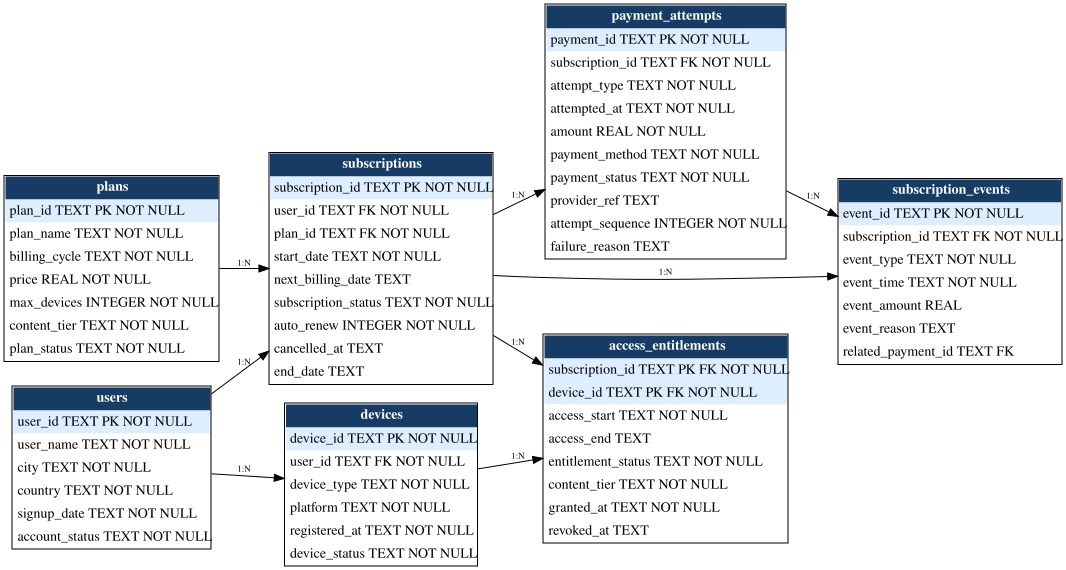

In [ ]:
# SQL DEVELOPER WORKSPACE - ER-1
# TODO: Complete all seven table definitions and all eight relationships.
# Use strings such as: "column_name TEXT PK/FK/NOT NULL"

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

developer_tables = {
    "users": [
        "user_id TEXT PK NOT NULL",
        "user_name TEXT NOT NULL",
        "city TEXT NOT NULL",
        "country TEXT NOT NULL",
        "signup_date TEXT NOT NULL",
        "account_status TEXT NOT NULL",
    ],
    "plans": [
        # TODO: Add the required columns.
        # ---------------DONE---------------
        "plan_id TEXT PK NOT NULL",
        "plan_name TEXT NOT NULL",
        "billing_cycle TEXT NOT NULL",
        "price REAL NOT NULL",
        "max_devices INTEGER NOT NULL",
        "content_tier TEXT NOT NULL",
        "plan_status TEXT NOT NULL",
    ],
    "subscriptions": [
        # TODO: Add the required columns.
        # ---------------DONE---------------
        "subscription_id TEXT PK NOT NULL",
        "user_id TEXT FK NOT NULL",
        "plan_id TEXT FK NOT NULL",
        "start_date TEXT NOT NULL",
        "next_billing_date TEXT",
        "subscription_status TEXT NOT NULL",
        "auto_renew INTEGER NOT NULL",
        "cancelled_at TEXT",
        "end_date TEXT",
    ],
    "devices": [
        # TODO: Add the required columns.
        # ---------------DONE---------------
        "device_id TEXT PK NOT NULL",
        "user_id TEXT FK NOT NULL",
        "device_type TEXT NOT NULL",
        "platform TEXT NOT NULL",
        "registered_at TEXT NOT NULL",
        "device_status TEXT NOT NULL",
    ],
    "payment_attempts": [
        # TODO: Add the required columns.
        # ---------------DONE---------------
        "payment_id TEXT PK NOT NULL",
        "subscription_id TEXT FK NOT NULL",
        "attempt_type TEXT NOT NULL",
        "attempted_at TEXT NOT NULL",
        "amount REAL NOT NULL",
        "payment_method TEXT NOT NULL",
        "payment_status TEXT NOT NULL",
        "provider_ref TEXT",
        "attempt_sequence INTEGER NOT NULL",
        "failure_reason TEXT",
    ],
    "subscription_events": [
        # TODO: Add the required columns.
        # ---------------DONE---------------
        "event_id TEXT PK NOT NULL",
        "subscription_id TEXT FK NOT NULL",
        "event_type TEXT NOT NULL",
        "event_time TEXT NOT NULL",
        "event_amount REAL",
        "event_reason TEXT",
        "related_payment_id TEXT FK",
    ],
    "access_entitlements": [
        # TODO: Add the required columns, including the composite key.
        # ---------------DONE---------------
        "subscription_id TEXT PK FK NOT NULL",
        "device_id TEXT PK FK NOT NULL",
        "access_start TEXT NOT NULL",
        "access_end TEXT",
        "entitlement_status TEXT NOT NULL",
        "content_tier TEXT NOT NULL",
        "granted_at TEXT NOT NULL",
        "revoked_at TEXT",
    ],
}

developer_relationships = [
    ("users", "user_id", "subscriptions", "user_id", "1:N"),
    # TODO: Add the remaining relationships in the same tuple format.
    # ---------------DONE---------------
    ("plans", "plan_id", "subscriptions", "plan_id", "1:N"),
    ("users", "user_id", "devices", "user_id", "1:N"),
    ("subscriptions", "subscription_id", "payment_attempts", "subscription_id", "1:N"),
    ("subscriptions", "subscription_id", "subscription_events", "subscription_id", "1:N"),
    ("payment_attempts", "payment_id", "subscription_events", "related_payment_id", "1:N"),
    ("subscriptions", "subscription_id", "access_entitlements", "subscription_id", "1:N"),
    ("devices", "device_id", "access_entitlements", "device_id", "1:N"),
]

developer_er_diagram = validate_and_draw_er(developer_tables, developer_relationships)

### Expected Output - ER-1

After the design is complete, the cell should display:

- `ER design check: Passed`
- Seven connected table boxes
- Primary-key fields highlighted
- Eight validated relationships
- A composite primary key in `access_entitlements` using `subscription_id + device_id`

**Hint:** Start with users and plans, connect subscriptions and devices, then add billing, lifecycle events, and the entitlement bridge.


### **Explanation**
The objective here is to define the seven core entities of the subscription management system, establish their relationships, and represent the complete structure through an ER diagram.

For this exercise, I have used the database schema prepared in the previous section as the reference.

---

#### 1. Defining the seven tables
Here, I have defined the structure of all seven core tables.

These are `users`, `plans`, `subscriptions`, `devices`, `payment_attempts`, `subscription_events`, and `access_entitlements`.

Each table represents a distinct component of the subscription ecosystem.

For example, the `users` table stores customer information, `plans` contains the subscription packages, and `subscriptions` connects users with their selected plans.

Similarly, `devices` stores registered devices, `payment_attempts` maintains billing transactions, and `subscription_events` records lifecycle activities such as renewals, cancellations, refunds, and expirations.

Finally, `access_entitlements` maintains the access granted to individual devices under a subscription.

---

#### 2. Defining the relationships
After defining the tables, I have established eight relationships between them.

Most of these are one-to-many relationships.

For example, one user can have multiple subscriptions and multiple registered devices. Similarly, one subscription can have multiple payment attempts, multiple lifecycle events, and multiple access entitlements.

Payment attempts are also linked to subscription events through the related payment reference.

These relationships establish how information across different tables is connected and help maintain the logical integrity of the database design.

---
#### 3. Composite primary key
One important design element here is the composite primary key in the `access_entitlements` table.

Instead of relying on a single column, I have used the combination of `subscription_id` and `device_id` to uniquely identify an entitlement record.

This is appropriate because the access entitlement is maintained at the subscription-device level.

---
#### 4. ER diagram and validation
Once the table definitions and relationships are complete, I have passed them to the validation and visualization function.

The function checks the presence of all seven tables, their required fields, primary-key and foreign-key markers, the composite key, and all eight relationships.

As shown in the output, every validation check has returned True, and the overall result is ER design check: Passed.

The notebook then renders the final Entity Relationship diagram, providing a visual representation of the complete database structure.

---
So, this completes the database design exercise. I have defined seven core entities, established eight relationships, implemented the composite primary key, and successfully validated the ER structure.

With the database architecture established, I can now move beyond the design stage and start interacting with the system through HTTP-based API operations.

# 3. API Operations

Complete five independent HTTP activities against the temporary internal billing API. Mutable records are reset before each activity so reruns remain safe.

In [ ]:
display(api_documentation)

,Method,Endpoint,Purpose,Expected status
0,GET,/users,Read account master records,200
1,GET,/plans,Read plan catalog records,200
2,GET,/subscriptions,Read subscription lifecycle records,200
3,GET,/devices,Read registered device records,200
4,GET,/payment_attempts,Read billing attempts with filters and pagination,200
5,GET,/payment_attempts/{id},Read one billing attempt,200 / 404
6,POST,/payment_attempts,Create one billing attempt,201 / 400 / 409
7,PUT,/payment_attempts/{id},Replace one billing attempt completely,200 / 400 / 404
8,PATCH,/payment_attempts/{id},Update selected billing-attempt fields,200 / 404
9,DELETE,/payment_attempts/{id},Delete one billing attempt,200 / 404


### **Explanation**
The documentation provides an overview of the available endpoints, their corresponding HTTP methods, their purpose, and the expected response status codes.

For example, GET is used to retrieve records, POST creates a new billing attempt, PUT replaces an existing record, PATCH updates selected fields, and DELETE removes a record.

The API also provides endpoints for users, plans, subscriptions, devices, payment attempts, subscription events, and access entitlements.

## API-Q1 - Fetch Filtered Successful Renewal Attempts

**Business requirement:** Billing Operations needs five successful UPI renewal attempts for a quick API filter check.

**How to approach:** Call `/payment_attempts` with `limit`, `attempt_type`, `payment_status`, and `payment_method` query parameters.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q1
api_q1_response = None

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

# TODO: Write requests.get(...) using /payment_attempts.
# Include limit=5, attempt_type=RENEWAL, payment_status=SUCCESS, payment_method=UPI.

# ---------------DONE---------------

api_q1_response = requests.get(
    f"{API_BASE_URL}/payment_attempts",
    params={
        "limit": 5,
        "attempt_type": "RENEWAL",
        "payment_status": "SUCCESS",
        "payment_method": "UPI",
    },
    timeout=5
)

validate_api_q1(api_q1_response)


,payment_id,subscription_id,attempt_type,attempted_at,amount,payment_method,payment_status,provider_ref,attempt_sequence,failure_reason
0,PAY000001,S0001,RENEWAL,2026-07-11 17:13:00,499.0,UPI,SUCCESS,GATE-0000001,2,None
1,PAY000002,S0002,RENEWAL,2026-07-21 11:26:00,1499.0,UPI,SUCCESS,GATE-0000002,3,None
2,PAY000003,S0003,RENEWAL,2026-07-31 22:39:00,299.0,UPI,SUCCESS,GATE-0000003,1,None
3,PAY000004,S0004,RENEWAL,2026-07-10 16:52:00,899.0,UPI,SUCCESS,GATE-0000004,2,None
4,PAY000005,S0005,RENEWAL,2026-07-20 10:05:00,149.0,UPI,SUCCESS,GATE-0000005,3,None


,Validation check,Result
0,HTTP 200,True
1,Exactly five records,True
2,Renewal attempts,True
3,Successful status,True
4,UPI method,True


Overall status: Passed


### Expected Output - API-Q1

- HTTP status: `200`
- Records returned: `5`
- Every record has `attempt_type = RENEWAL`
- Every record has `payment_status = SUCCESS`
- Every record has `payment_method = UPI`

**Hint:** Use `requests.get(..., params={...}, timeout=5)`.

### **EXPLANATION**
In this problem, the Billing Operations team requires five successful UPI renewal attempts for a quick API filter check.

For this, I have used the GET method on the `/payment_attempts` endpoint.

```
api_q1_response = requests.get(
    f"{API_BASE_URL}/payment_attempts",
    params={
        "limit": 5,
        "attempt_type": "RENEWAL",
        "payment_status": "SUCCESS",
        "payment_method": "UPI",
    },
    timeout=5
)
```


Here, I have used `requests.get()` to send an HTTP GET request to the payment attempts endpoint.

The params argument contains four query parameters:
- limit = 5 --> restricts the response to five records.
- attempt_type = RENEWAL --> filters for renewal attempts.
- payment_status = SUCCESS --> selects only successful payments.
- payment_method = UPI --> restricts the results to UPI transactions.
The timeout is set to five seconds, so the request does not wait indefinitely for a response.

Once the response is received, I have passed it to `validate_api_q1()`.

This validation function checks whether the API returned HTTP status 200, exactly five records, and whether every returned record satisfies all three filtering conditions.

---
As we can see in the output that the API successfully returns five payment records. We can see that all five are renewal attempts, all have a successful payment status, and all use UPI as the payment method.

The validation table confirms that every condition has passed, and the overall status is also marked as Passed.

---

This exercise demonstrates how query parameters can be used to retrieve a specific subset of billing records without fetching the entire payment table.

## API-Q2 - Create a Billing Attempt with POST

**Business requirement:** Billing Operations needs a provided renewal attempt created through the internal API.

**How to approach:** POST the provided JSON payload to `/payment_attempts`.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q2

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

remove_api_practice_record("PAY_API_POST_001")

new_payment_payload = {
    "payment_id": "PAY_API_POST_001", "subscription_id": "S0005", "attempt_type": "RENEWAL",
    "attempted_at": "2026-08-01 09:00:00", "amount": 149.0, "payment_method": "UPI",
    "payment_status": "SUCCESS", "provider_ref": "API-POST-001", "attempt_sequence": 1, "failure_reason": None,
}

api_q2_response = None

# TODO: Write requests.post(...) with the provided JSON payload and timeout=5.
# ---------------DONE---------------
api_q2_response = requests.post(
    f"{API_BASE_URL}/payment_attempts",
    json = new_payment_payload,
    timeout = 5
)

validate_api_q2(api_q2_response, new_payment_payload)


,payment_id,subscription_id,attempt_type,attempted_at,amount,payment_method,payment_status,provider_ref,attempt_sequence,failure_reason
0,PAY_API_POST_001,S0005,RENEWAL,2026-08-01 09:00:00,149.0,UPI,SUCCESS,API-POST-001,1,None


,Validation check,Result
0,HTTP 201,True
1,Expected payment ID,True
2,Payload fields,True


Overall status: Passed


### Expected Output - API-Q2

- HTTP status: `201`
- `payment_id = PAY_API_POST_001`
- Returned payload matches every provided field

**Hint:** Use `requests.post(..., json=new_payment_payload, timeout=5)`.

### **EXPLANATION**
This problem demonstrates how to create a new billing attempt using the POST method.

The business requirement is to create a provided renewal payment attempt through the internal API.

For this exercise, I have first prepared a JSON payload containing all the required payment information.

The payload contains the payment ID, subscription ID, attempt type, attempted date and time, amount, payment method, payment status, provider reference, attempt sequence, and failure reason.

For this particular example, the payment amount is 149 rupees, the payment method is UPI, and the payment status is SUCCESS.

Before sending the request, I have also calld `remove_api_practice_record()` with the same payment ID. This ensures that an earlier practice record with this ID does not interfere with a fresh execution.

```
api_q2_response = requests.post(
    f"{API_BASE_URL}/payment_attempts",
    json = new_payment_payload,
    timeout = 5
)
```

Here, I have used `requests.post()` to send the payload to the `/payment_attempts` endpoint.

Unlike the GET request, which retrieves existing information, POST submits new data to create a resource.

The json parameter sends the dictionary as a JSON request body, while the timeout is again set to five seconds.

After receiving the response, I have passed it to `validate_api_q2()`, which checks the HTTP status, the expected payment ID, and whether the returned payload matches the information I submitted.

---
As we can see in the output, the API successfully creates the billing attempt and returns the newly created payment record.

The response status is HTTP 201, which indicates that the resource has been created successfully.

The validation confirms that the payment ID is correct and that the returned payload matches the provided fields. All checks pass, and the overall status is Passed.

---

This exercise demonstrates how a new billing record can be created through an API and how the response can be validated against the original request payload.

## API-Q3 - Replace a Complete Billing Attempt with PUT

**Business requirement:** Replace a reset practice billing attempt with a complete record.

**How to approach:** PUT the full replacement object to `/payment_attempts/PAY_API_PUT_001`.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q3

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

reset_api_practice_record("PAY_API_PUT_001")

replacement_payload = {
    "payment_id": "PAY_API_PUT_001", "subscription_id": "S0010", "attempt_type": "RENEWAL",
    "attempted_at": "2026-08-01 10:15:00", "amount": 499.0, "payment_method": "NET_BANKING",
    "payment_status": "SUCCESS", "provider_ref": "API-PUT-REPLACED", "attempt_sequence": 2, "failure_reason": None,
}

api_q3_response = None

# TODO: Write requests.put(...) and send the complete replacement payload.
# ---------------DONE---------------
api_q3_response = requests.put(
    f"{API_BASE_URL}/payment_attempts/PAY_API_PUT_001",
    json = replacement_payload,
    timeout = 5
)


validate_api_q3(api_q3_response, replacement_payload)


,payment_id,subscription_id,attempt_type,attempted_at,amount,payment_method,payment_status,provider_ref,attempt_sequence,failure_reason
0,PAY_API_PUT_001,S0010,RENEWAL,2026-08-01 10:15:00,499.0,NET_BANKING,SUCCESS,API-PUT-REPLACED,2,None


,Validation check,Result
0,HTTP 200,True
1,Complete replacement fields,True
2,Every value replaced,True


Overall status: Passed


### Expected Output - API-Q3

- HTTP status: `200`
- Every field matches the complete replacement object
- No baseline values remain unexpectedly

**Hint:** PUT represents full replacement, so send every required field.

### **EXPLANATION**
The third problem demonstrates the PUT method. The requirement is to replace an existing practice billing attempt with a complete new record.

For this exercise, I have used the payment ID `PAY_API_PUT_001` and prepare a complete replacement payload containing all the required payment information.

The practice record is reset before the request, ensuring that the exercise starts from a known state.

Here, I have used `requests.put()` to send the complete replacement object to the specific payment endpoint.

An important distinction between PUT and PATCH is that PUT is intended for replacing the complete resource. Therefore, I provide all the required fields rather than sending only the fields I want to modify.

The replacement record contains a renewal payment of 499 rupees through Net Banking, with a successful payment status.

---

As per the output, the API returns HTTP 200, indicating that the request was processed successfully.

The validation checks confirm three things: the HTTP response is correct, all required replacement fields are present, and every value matches the replacement payload.

All three checks pass, and the overall status is marked as Passed.

## API-Q4 - Update Selected Billing Fields with PATCH

**Business requirement:** Update only payment status and failure reason while preserving all other values.

**How to approach:** PATCH the two provided fields to the reset practice record.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q4

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

api_q4_baseline = reset_api_practice_record("PAY_API_PATCH_001")
patch_payload = {"payment_status": "FAILED", "failure_reason": "AUTHENTICATION_FAILED"}

api_q4_response = None

# TODO: Write requests.patch(...) with only the provided patch fields.
# ---------------DONE---------------

api_q4_response = requests.patch(
    f"{API_BASE_URL}/payment_attempts/PAY_API_PATCH_001",
    json = patch_payload,
    timeout = 5
)


validate_api_q4(api_q4_response, api_q4_baseline, patch_payload)


,payment_id,subscription_id,attempt_type,attempted_at,amount,payment_method,payment_status,provider_ref,attempt_sequence,failure_reason
0,PAY_API_PATCH_001,S0007,RENEWAL,2026-08-01 08:35:00,299.0,UPI,FAILED,API-PATCH-BASE,1,AUTHENTICATION_FAILED


,Validation check,Result
0,HTTP 200,True
1,Targeted fields changed,True
2,Untargeted fields unchanged,True


Overall status: Passed


### Expected Output - API-Q4

- HTTP status: `200`
- `payment_status = FAILED`
- `failure_reason = AUTHENTICATION_FAILED`
- Untargeted fields are unchanged

**Hint:** Send only the fields that should change.

### **EXPLANATION**
The fourth problem demonstrates PATCH, which is used when we want to modify only selected fields of an existing record without replacing the entire resource.

Here, the requirement is to update the payment status and failure reason while preserving all other existing information.
```
patch_payload = {"payment_status": "FAILED", "failure_reason": "AUTHENTICATION_FAILED"}
```
First, the practice record is reset, and its original state is stored as the baseline.

I then prepare a PATCH payload containing only two fields: the payment status is changed to `FAILED`, and the failure reason is set to `AUTHENTICATION_FAILED`.

The PATCH request sends these two fields to the specific payment endpoint.

Unlike PUT, I do not send the entire payment record because the objective is to make a partial update.

---

The output shows that the API returns HTTP 200.

More importantly, the validation checks confirm not only that the two targeted fields have changed, but also that all the untargeted fields remain unchanged.

This is the key distinction demonstrated by this exercise: PATCH updates selected fields while preserving the rest of the record.

All validation checks pass.

## API-Q5 - GET -> DELETE -> GET Verification

**Business requirement:** Prove that a reset practice billing attempt is available, can be deleted, and is unavailable afterward.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q5

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

reset_api_practice_record("PAY_API_DELETE_001")

api_q5_read_before = None
api_q5_delete = None
api_q5_read_after = None

# TODO: Perform GET -> DELETE -> GET for PAY_API_DELETE_001.
# ---------------DONE---------------

api_q5_read_before = requests.get(
    f"{API_BASE_URL}/payment_attempts/PAY_API_DELETE_001",
    timeout = 5
)

api_q5_delete = requests.delete(
    f"{API_BASE_URL}/payment_attempts/PAY_API_DELETE_001",
    timeout = 5
)

api_q5_read_after = requests.get(
    f"{API_BASE_URL}/payment_attempts/PAY_API_DELETE_001",
    timeout = 5
)

validate_api_q5(api_q5_read_before, api_q5_delete, api_q5_read_after)


,Request,HTTP status
0,GET before,200
1,DELETE,200
2,GET after,404


Expected status sequence: 200 -> 200 -> 404
Actual status sequence: 200 -> 200 -> 404
Overall status: Passed


### Expected Output - API-Q5

| Step | Expected HTTP status |
|---|---:|
| GET before delete | 200 |
| DELETE | 200 |
| GET after delete | 404 |

**Hint:** Use the same record ID in all three requests.

### **EXPLANATION**
This API problem demonstrates the DELETE method.

However, instead of simply sending a DELETE request, I have used a three-step verification process to establish that the record actually becomes unavailable after deletion.

First, I have reset the practice record with the ID `PAY_API_DELETE_001`.

I have then performed three consecutive requests using the same payment ID.

The first GET request verifies that the record exists before deletion.

Next, the DELETE request attempts to remove the record.

Finally, I have executed another GET request to check whether the same record is still accessible.

---

| HTTP response verification |  |
| --- | --- |
| GET before deletion | 200 |
| DELETE request | 200 |
| GET after deletion | 404 |

The output shows that the first request returns HTTP 200, confirming that the record exists.

The DELETE request also returns HTTP 200, indicating successful deletion.

Finally, the second GET request returns HTTP 404, which confirms that the record is no longer available through the API.

The validation function checks the complete expected sequence — 200, 200, and 404 — and marks the activity as Passed.

# 4. SQL Developer Questions

In [ ]:
schema_catalog = build_schema_catalog(conn)
display(schema_catalog)
TABLE_TO_PREVIEW = "payment_attempts"
display(run_query(f"SELECT * FROM {TABLE_TO_PREVIEW} LIMIT 5"))

,Table,Column count,Columns
0,access_entitlements,8,"subscription_id, device_id, access_start, access_end, en..."
1,api_ingestion_runs,7,"run_id, resource_name, fetched_at, rows_received, rows_l..."
2,devices,6,"device_id, user_id, device_type, platform, registered_at..."
3,payment_attempts,10,"payment_id, subscription_id, attempt_type, attempted_at,..."
4,plans,7,"plan_id, plan_name, billing_cycle, price, max_devices, c..."
5,subscription_events,7,"event_id, subscription_id, event_type, event_time, event..."
6,subscription_exceptions,10,"exception_id, exception_type, severity, subscription_id,..."
7,subscription_ledger,8,"ledger_id, subscription_id, user_id, ledger_type, amount..."
8,subscriptions,9,"subscription_id, user_id, plan_id, start_date, next_bill..."
9,users,6,"user_id, user_name, city, country, signup_date, account_..."


,payment_id,subscription_id,attempt_type,attempted_at,amount,payment_method,payment_status,provider_ref,attempt_sequence,failure_reason
0,PAY000001,S0001,RENEWAL,2026-07-11 17:13:00,499.0,UPI,SUCCESS,GATE-0000001,2,None
1,PAY000002,S0002,RENEWAL,2026-07-21 11:26:00,1499.0,UPI,SUCCESS,GATE-0000002,3,None
2,PAY000003,S0003,RENEWAL,2026-07-31 22:39:00,299.0,UPI,SUCCESS,GATE-0000003,1,None
3,PAY000004,S0004,RENEWAL,2026-07-10 16:52:00,899.0,UPI,SUCCESS,GATE-0000004,2,None
4,PAY000005,S0005,RENEWAL,2026-07-20 10:05:00,149.0,UPI,SUCCESS,GATE-0000005,3,None


## 4A. SQL Foundations and Multiple Tables

### Q1 - Largest Successful Renewal Charges

**Stakeholder:** Revenue Assurance Lead  
**Business requirement:** Identify the ten largest successful renewal charges so high-value billing can be checked first.  
**Tables to use:** `payment_attempts`, `subscriptions`, `users`, `plans`  
**How to approach:** Join billing to subscription, user, and plan data; filter successful renewals; sort by amount descending; return ten rows.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q1

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q1_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    pa.payment_id,
    pa.subscription_id,
    s.user_id,
    u.city,
    pl.plan_name,
    pa.amount,
    pa.payment_method,
    pa.attempted_at
FROM payment_attempts AS pa
    JOIN subscriptions AS s
        ON pa.subscription_id = s.subscription_id
    JOIN users AS u
        ON s.user_id = u.user_id
    JOIN plans AS pl
        ON s.plan_id = pl.plan_id
WHERE
    pa.attempt_type = 'RENEWAL'
    AND pa.payment_status = 'SUCCESS'
ORDER BY
    pa.amount DESC,
    pa.attempted_at ASC
LIMIT 10;

"""
q1 = run_developer_query("Q1", q1_sql)


,payment_id,subscription_id,user_id,city,plan_name,amount,payment_method,attempted_at
0,PAY001228,S0112,U0112,Bengaluru,Premium Annual,1536.0,UPI,2026-07-25 12:36:00
1,PAY001221,S0105,U0105,Chennai,Premium Annual,1536.0,CARD,2026-07-25 17:15:00
2,PAY000031,S0031,U0031,Ahmedabad,Premium Annual,1499.0,UPI,2026-07-01 07:43:00
3,PAY001099,S0019,U0019,Mumbai,Premium Annual,1499.0,UPI,2026-07-01 08:07:00
4,PAY000062,S0062,U0062,Kolkata,Premium Annual,1499.0,UPI,2026-07-01 08:26:00
5,PAY000093,S0093,U0093,Kolkata,Premium Annual,1499.0,UPI,2026-07-01 09:09:00
6,PAY001130,S0050,U0050,Mumbai,Premium Annual,1499.0,UPI,2026-07-01 09:50:00
7,PAY001161,S0081,U0081,Bengaluru,Premium Annual,1499.0,UPI,2026-07-01 10:33:00
8,PAY000124,S0124,U0004,Chennai,Premium Annual,1499.0,UPI,2026-07-01 10:52:00
9,PAY001192,S0112,U0112,Bengaluru,Premium Annual,1499.0,UPI,2026-07-01 11:16:00


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q1

| Column | Requirement |
|---|---|
| `payment_id` | Required output column |
| `subscription_id` | Required output column |
| `user_id` | Required output column |
| `city` | Required output column |
| `plan_name` | Required output column |
| `amount` | Required output column |
| `payment_method` | Required output column |
| `attempted_at` | Required output column |

**Expected row count:** `10`

**Expected first row after the required ordering:**

```text
| PAY001228 | S0112 | U0112 | Bengaluru | Premium Annual | 1536.00 | UPI | 2026-07-25 12:36:00 |
```

**Hint:** `JOIN`, `WHERE`, `ORDER BY ... DESC`, `LIMIT`.

#### **EXPLANATION**
This question is to identify the ten largest successful renewal charges. For this, I have joined four tables: `payment_attempts`, `subscriptions`, `users`, and `plans`.

The query filters only successful renewal transactions, sorts them by payment amount in descending order, and returns the top ten records. I have also used the transaction timestamp as a secondary sorting condition.

---

The output shows that the highest charge is ₹1,536, associated with the Premium Annual plan. The query returns exactly ten records, and all validation checks pass.

### Q2 - Plan-Level Successful Revenue

**Stakeholder:** Subscription Finance Lead  
**Business requirement:** Show plan-level successful-payment volume and revenue, keeping only plans with at least 150 successful payments and INR 30,000 in value.  
**Tables to use:** `payment_attempts`, `subscriptions`, `plans`  
**How to approach:** Group successful payments by plan; calculate count, sum, and average; filter groups with HAVING.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q2

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q2_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    pl.plan_id,
    pl.plan_name,
    COUNT(pa.payment_id) AS successful_payments,
    ROUND(SUM(pa.amount), 2) AS total_revenue,
    ROUND(AVG(pa.amount), 2) AS average_payment
FROM payment_attempts AS pa
    JOIN subscriptions AS s
        ON pa.subscription_id = s.subscription_id
    JOIN plans AS pl
        ON s.plan_id = pl.plan_id
WHERE
    pa.payment_status = 'SUCCESS'
GROUP BY
    pl.plan_id,
    pl.plan_name
HAVING
    COUNT(pa.payment_id) >= 150
    AND SUM(pa.amount) >= 30000
ORDER BY
    total_revenue DESC;

"""
q2 = run_developer_query("Q2", q2_sql)


,plan_id,plan_name,successful_payments,total_revenue,average_payment
0,P005,Premium Annual,228,341846.0,1499.32
1,P004,Standard Annual,223,200551.0,899.33
2,P003,Premium Monthly,228,113883.0,499.49
3,P002,Standard Monthly,224,67050.0,299.33
4,P001,Mobile Monthly,227,33934.0,149.49


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q2

| Column | Requirement |
|---|---|
| `plan_id` | Required output column |
| `plan_name` | Required output column |
| `successful_payments` | Required output column |
| `total_revenue` | Required output column |
| `average_payment` | Required output column |

**Expected row count:** `5`

**Expected first row after the required ordering:**

```text
| P005 | Premium Annual | 228 | 341846.00 | 1499.32 |
```

**Hint:** `GROUP BY`, `COUNT`, `SUM`, `AVG`, `HAVING`.

#### **EXPLANATION**
The second question shifts from individual transactions to plan-level revenue analysis. I have joined the `payment_attempts`, `subscriptions`, and `plans` tables, and consider only successful payments.

Using `GROUP BY`, I have calculated the number of successful payments, total revenue, and average payment for each plan.

The `HAVING` clause then filters the aggregated results, retaining only plans with at least 150 successful payments and revenue of at least ₹30,000.

---

The output contains all five plans, ranked by total revenue. Premium Annual leads with 228 successful payments and total revenue of ₹3,41,846. The query also passes all validation checks.

### Q3 - Reconcile Recent Charges with Usable Active Access

**Stakeholder:** Access Operations Lead  
**Business requirement:** Classify recent successful renewal charges as access active or access missing. Usable access requires an ACTIVE entitlement attached to an ACTIVE device.  
**Tables to use:** `payment_attempts`, `subscriptions`, `users`, `access_entitlements`, `devices`  
**How to approach:** Join recent successful renewals directly to ACTIVE entitlements and ACTIVE devices, group by payment, count usable entitlements, and classify with CASE. Do not use a CTE or window function in this foundations section.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q3

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q3_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    pa.payment_id,
    pa.subscription_id,
    u.user_id,
    pa.amount,
    COUNT(d.device_id) AS active_entitlements,
    CASE
        WHEN COUNT(d.device_id) > 0
            THEN 'ACCESS_ACTIVE'
        ELSE 'ACCESS_MISSING'
    END AS access_status
FROM payment_attempts AS pa
    JOIN subscriptions AS s
        ON pa.subscription_id = s.subscription_id
    JOIN users AS u
        ON s.user_id = u.user_id
    LEFT JOIN access_entitlements AS ae
        ON s.subscription_id = ae.subscription_id
        AND ae.entitlement_status = 'ACTIVE'
        AND ae.access_start <= pa.attempted_at
        AND (
            ae.access_end IS NULL
            OR ae.access_end >= pa.attempted_at
        )
    LEFT JOIN devices AS d
        ON ae.device_id = d.device_id
        AND d.device_status = 'ACTIVE'
WHERE
    pa.attempt_type = 'RENEWAL'
    AND pa.payment_status = 'SUCCESS'
    AND pa.attempted_at >= '2026-07-29 00:00:00'
    AND pa.attempted_at < '2026-08-01 00:00:00'
    AND s.subscription_status = 'ACTIVE'
GROUP BY
    pa.payment_id,
    pa.subscription_id,
    u.user_id,
    pa.amount,
    pa.attempted_at
ORDER BY
    access_status DESC,
    s.subscription_id ASC,
    pa.attempted_at ASC;
"""

q3 = run_developer_query("Q3", q3_sql)

,payment_id,subscription_id,user_id,amount,active_entitlements,access_status
0,PAY001239,S0001,U0001,499.0,0,ACCESS_MISSING
1,PAY000721,S0001,U0001,499.0,0,ACCESS_MISSING
2,PAY000181,S0001,U0001,499.0,0,ACCESS_MISSING
3,PAY001240,S0002,U0002,1499.0,0,ACCESS_MISSING
4,PAY000362,S0002,U0002,1499.0,0,ACCESS_MISSING
...,...,...,...,...,...,...
84,PAY000127,S0127,U0007,149.0,1,ACCESS_ACTIVE
85,PAY000489,S0129,U0009,1499.0,2,ACCESS_ACTIVE
86,PAY000130,S0130,U0010,299.0,1,ACCESS_ACTIVE
87,PAY000311,S0131,U0011,899.0,1,ACCESS_ACTIVE


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q3

| Column | Requirement |
|---|---|
| `payment_id` | Required output column |
| `subscription_id` | Required output column |
| `user_id` | Required output column |
| `amount` | Required output column |
| `active_entitlements` | Required output column |
| `access_status` | Required output column |

**Expected row count:** `89`

**Expected first row after the required ordering:**

```text
| PAY001239 | S0001 | U0001 | 499.00 | 0 | ACCESS_MISSING |
```

**Hint:** direct `LEFT JOIN`, `GROUP BY`, `COUNT`, and `CASE`; no CTE or window function is needed.

#### **EXPLANATION**
The Q3 focuses on reconciling successful renewal payments with actual subscription access.

I have joined five tables and used `LEFT JOIN` to check whether each recent successful renewal has an active entitlement linked to an active device. I have then used `COUNT` and a `CASE` expression to classify each payment as either `ACCESS_ACTIVE` or `ACCESS_MISSING`.

---

The result contains 89 payment records.

The important point is that a successful payment does not automatically guarantee usable access. The query identifies that distinction, and all validation checks pass.

### Q4 - Charged Without Usable Active Access

**Stakeholder:** Customer Support Escalations Lead  
**Business requirement:** List the latest recent successful renewal charge for each active subscription that has no usable access. Usable access requires an ACTIVE entitlement on an ACTIVE device.  
**Tables to use:** `payment_attempts`, `subscriptions`, `users`, `access_entitlements`, `devices`  
**How to approach:** Use a payment self anti-join to keep only the latest recent successful renewal per subscription, then use access/device left joins plus `GROUP BY`/`HAVING` to isolate subscriptions with no usable active access. Do not use a CTE or window function in this foundations section.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q4

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q4_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    pa.payment_id,
    pa.subscription_id,
    s.user_id,
    u.city,
    pa.amount,
    pa.attempted_at
FROM payment_attempts AS pa
    JOIN subscriptions AS s
        ON pa.subscription_id = s.subscription_id
    JOIN users AS u
        ON s.user_id = u.user_id
    LEFT JOIN payment_attempts AS newer
        ON newer.subscription_id = pa.subscription_id
        AND newer.attempt_type = 'RENEWAL'
        AND newer.payment_status = 'SUCCESS'
        AND newer.attempted_at > pa.attempted_at
        AND newer.attempted_at >= '2026-07-29 00:00:00'
        AND newer.attempted_at < '2026-08-01 00:00:00'
    LEFT JOIN access_entitlements AS ae
        ON ae.subscription_id = s.subscription_id
        AND ae.entitlement_status = 'ACTIVE'
        AND ae.access_start <= pa.attempted_at
        AND (
            ae.access_end IS NULL
            OR ae.access_end >= pa.attempted_at
        )
    LEFT JOIN devices AS d
        ON d.device_id = ae.device_id
        AND d.device_status = 'ACTIVE'
WHERE
    pa.attempt_type = 'RENEWAL'
    AND pa.payment_status = 'SUCCESS'
    AND s.subscription_status = 'ACTIVE'
    AND pa.attempted_at >= '2026-07-29 00:00:00'
    AND pa.attempted_at < '2026-08-01 00:00:00'
    AND newer.payment_id IS NULL
GROUP BY
    pa.payment_id,
    pa.subscription_id,
    s.user_id,
    u.city,
    pa.amount,
    pa.attempted_at
HAVING
    COUNT(d.device_id) = 0
ORDER BY
    s.subscription_id ASC,
    pa.attempted_at DESC,
    pa.payment_id ASC;

"""

q4 = run_developer_query("Q4", q4_sql)


,payment_id,subscription_id,user_id,city,amount,attempted_at
0,PAY000181,S0001,U0001,Pune,499.0,2026-07-31 08:13:00
1,PAY000362,S0002,U0002,Delhi,1499.0,2026-07-30 10:26:00
2,PAY001211,S0003,U0003,Ahmedabad,299.0,2026-07-31 22:41:00
3,PAY000184,S0004,U0004,Chennai,899.0,2026-07-30 07:52:00
4,PAY001243,S0005,U0005,Mumbai,149.0,2026-07-29 13:20:00
5,PAY001214,S0006,U0006,Kolkata,499.0,2026-07-30 21:20:00
6,PAY001245,S0007,U0007,Chennai,1499.0,2026-07-29 15:28:00
7,PAY001246,S0008,U0008,Mumbai,299.0,2026-07-29 16:32:00
8,PAY000009,S0009,U0009,Kolkata,899.0,2026-07-29 20:57:00
9,PAY001248,S0010,U0010,Hyderabad,149.0,2026-07-29 08:40:00


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q4

| Column | Requirement |
|---|---|
| `payment_id` | Required output column |
| `subscription_id` | Required output column |
| `user_id` | Required output column |
| `city` | Required output column |
| `amount` | Required output column |
| `attempted_at` | Required output column |

**Expected row count:** `21`

**Expected first row after the required ordering:**

```text
| PAY000181 | S0001 | U0001 | Pune | 499.00 | 2026-07-31 08:13:00 |
```

**Hint:** self `LEFT JOIN`, access/device `LEFT JOIN`, `GROUP BY`, and `HAVING`; no CTE or window function is needed.

#### **EXPLANATION**
This query takes the reconciliation further. The objective is to identify the latest successful renewal charge for each active subscription that has no usable access.

The key technique here is a self `LEFT JOIN` on the payment table. By checking that no newer successful renewal exists, I have retained only the latest qualifying payment. I have then joined the entitlement and device tables and use `HAVING COUNT(d.device_id) = 0` to identify subscriptions without usable access.

---

The final output contains 21 records, and all validation checks pass.

This gives the customer support team a focused list of billing cases that may require investigation.

## 4B. SQL Functions, Set Operations, Subqueries, and CTEs

### Q5 - Refunded Users with Open Exceptions

**Stakeholder:** Subscription Operations Lead  
**Business requirement:** Find users who have a completed refund and also have at least one open operational exception.  
**Tables to use:** `users`, `subscriptions`, `subscription_events`, `subscription_exceptions`  
**How to approach:** Build the refunded-user set and open-exception-user set, intersect them, then return user details.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q5

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q5_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    u.user_id,
    u.user_name,
    u.city
FROM users AS u
    JOIN (
        SELECT s.user_id
        FROM subscriptions AS s
            JOIN subscription_events AS se
                ON se.subscription_id = s.subscription_id
        WHERE
            se.event_type = 'REFUND_COMPLETED'

        INTERSECT

        SELECT e.user_id
        FROM subscription_exceptions AS e
        WHERE
            e.status = 'OPEN'
        ) AS matching_users

        ON matching_users.user_id = u.user_id
ORDER BY
    u.user_id ASC;

"""

q5 = run_developer_query("Q5", q5_sql)


,user_id,user_name,city
0,U0021,Aarav Mehta,Chennai
1,U0022,Vivaan Iyer,Mumbai
2,U0023,Aditya Joshi,Kolkata
3,U0024,Arjun Sharma,Hyderabad
4,U0025,Sai Mehta,Bengaluru
5,U0026,Ishaan Iyer,Pune
6,U0027,Krishna Joshi,Delhi
7,U0028,Kabir Sharma,Bengaluru
8,U0029,Rohan Mehta,Pune
9,U0030,Dev Iyer,Delhi


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q5

| Column | Requirement |
|---|---|
| `user_id` | Required output column |
| `user_name` | Required output column |
| `city` | Required output column |

**Expected row count:** `20`

**Expected first row after the required ordering:**

```text
| U0021 | Aarav Mehta | Chennai |
```

**Hint:** `INTERSECT` plus joins.

#### **EXPLANATION**
This question is to identify users who have completed a refund and also have at least one open operational exception.

For this, I have created two separate user sets:
- one containing users associated with completed refunds, and
- another containing users with open exceptions.

I have then used the `INTERSECT` operator to find users common to both sets and join the result with the users table to retrieve their details.

---

The query returns 20 users. The first record is `U0021`, `Aarav Mehta`, from `Chennai`. All validation checks pass.

### Q6 - Subscriber Operational Risk Bands

**Stakeholder:** Operations Control Lead  
**Business requirement:** Create a readable risk view using account age and open/critical exception counts.  
**Tables to use:** `users`, `subscription_exceptions`  
**How to approach:** Format names/cities, calculate account age, coalesce missing counts, and classify risk with CASE.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q6

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q6_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

SELECT
    u.user_id,
    UPPER(u.user_name) AS user_name_upper,
    SUBSTR(u.city, 1, 3) AS city_code,
    CAST(
        julianday('2026-08-01') - julianday(u.signup_date) AS INTEGER
    ) AS account_age_days,
    COALESCE(COUNT(e.exception_id), 0) AS open_exceptions,
    COALESCE(SUM(CASE
                    WHEN e.severity = 'CRITICAL' THEN 1
                    ELSE 0
                  END),
            0) AS critical_exceptions,
    CASE
        WHEN COALESCE(SUM(CASE
                              WHEN e.severity = 'CRITICAL' THEN 1
                              ELSE 0
                          END),
                      0) >= 2
            THEN 'HIGH RISK'
        WHEN COALESCE(COUNT(e.exception_id), 0) >= 2
            THEN 'MEDIUM RISK'
        ELSE 'NORMAL'
    END AS risk_band
FROM users AS u
    LEFT JOIN subscription_exceptions AS e
        ON e.user_id = u.user_id
        AND e.status = 'OPEN'
GROUP BY
    u.user_id,
    u.user_name,
    u.city,
    u.signup_date
ORDER BY
    open_exceptions DESC,
    u.user_id ASC;

"""

q6 = run_developer_query("Q6", q6_sql)


,user_id,user_name_upper,city_code,account_age_days,open_exceptions,critical_exceptions,risk_band
0,U0001,AARAV MEHTA,Pun,913,3,3,HIGH RISK
1,U0003,ADITYA JOSHI,Ahm,853,3,3,HIGH RISK
2,U0005,SAI MEHTA,Mum,793,3,3,HIGH RISK
3,U0002,VIVAAN IYER,Del,883,2,2,HIGH RISK
4,U0004,ARJUN SHARMA,Che,823,2,2,HIGH RISK
...,...,...,...,...,...,...,...
115,U0116,KIARA SHARMA,Che,607,0,0,NORMAL
116,U0117,MEERA MEHTA,Mum,694,0,0,NORMAL
117,U0118,SAANVI IYER,Kol,664,0,0,NORMAL
118,U0119,RIYA JOSHI,Che,634,0,0,NORMAL


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q6

| Column | Requirement |
|---|---|
| `user_id` | Required output column |
| `user_name_upper` | Required output column |
| `city_code` | Required output column |
| `account_age_days` | Required output column |
| `open_exceptions` | Required output column |
| `critical_exceptions` | Required output column |
| `risk_band` | Required output column |

**Expected row count:** `120`

**Expected first row after the required ordering:**

```text
| U0001 | AARAV MEHTA | Pun | 913 | 3 | 3 | HIGH RISK |
```

**Hint:** `UPPER`, `SUBSTR`, date arithmetic, `CAST`, `COALESCE`, `CASE`.

#### **EXPLANATION**
The Q6 creates an operational risk classification for subscribers using their account age and open-exception counts.

Here, I have used functions such as `UPPER` and `SUBSTR` to format user details, date arithmetic with `julianday` to calculate account age, and `COALESCE` to handle missing exception counts. Finally, a `CASE` expression assigns each subscriber to `HIGH RISK`, `MEDIUM RISK`, or `NORMAL`.

---

The output contains all 120 users.

For example, users with at least two critical exceptions are classified as `HIGH RISK`. The query passes all validation checks.

### Q7 - Plans Above Average Revenue

**Stakeholder:** Product Finance Manager  
**Business requirement:** Identify plans whose successful-payment revenue is above the average plan revenue.  
**Tables to use:** `payment_attempts`, `subscriptions`, `plans`  
**How to approach:** Calculate revenue per plan, compute the scalar average of plan revenue, then filter above that benchmark.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q7

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q7_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH plan_revenue_cte AS (
    SELECT
        pl.plan_id,
        pl.plan_name,
        ROUND(SUM(pa.amount), 2) AS plan_revenue
    FROM plans AS pl
        JOIN subscriptions AS s
            ON s.plan_id = pl.plan_id
        JOIN payment_attempts AS pa
            ON pa.subscription_id = s.subscription_id
    WHERE
        pa.payment_status = 'SUCCESS'
    GROUP BY
        pl.plan_id,
        pl.plan_name
)

SELECT
    plan_id,
    plan_name,
    plan_revenue,
    ROUND((SELECT AVG(plan_revenue) FROM plan_revenue_cte), 2) AS average_plan_revenue
FROM plan_revenue_cte
WHERE
    plan_revenue > (SELECT AVG(plan_revenue) FROM plan_revenue_cte)
ORDER BY
    plan_revenue DESC,
    plan_id ASC;

"""

q7 = run_developer_query("Q7", q7_sql)


,plan_id,plan_name,plan_revenue,average_plan_revenue
0,P005,Premium Annual,341846.0,151452.8
1,P004,Standard Annual,200551.0,151452.8


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q7

| Column | Requirement |
|---|---|
| `plan_id` | Required output column |
| `plan_name` | Required output column |
| `plan_revenue` | Required output column |
| `average_plan_revenue` | Required output column |

**Expected row count:** `2`

**Expected first row after the required ordering:**

```text
| P005 | Premium Annual | 341846.00 | 151452.80 |
```

**Hint:** Standard CTE plus scalar subquery.

#### **EXPLANATION**
The Q7 focuses on identifying subscription plans whose successful-payment revenue is above the average revenue across all plans.

I have first used a CTE to calculate the total successful-payment revenue for each plan. Then, I have used a scalar subquery to calculate the average plan revenue and filter out plans that do not exceed this benchmark.

---

The output shows that the average plan revenue is ₹1,51,452.80. Only two plans exceed this value: `Premium Annual` with ₹3,41,846, and `Standard Annual` with ₹2,00,551. All validation checks pass.

### Q8 - Net Billing and Access State

**Stakeholder:** Revenue & Access Operations Lead  
**Business requirement:** Recalculate subscription-level successful charges minus completed refunds and show the active-entitlement count for the highest net-billed subscriptions.  
**Tables to use:** `subscriptions`, `users`, `plans`, `payment_attempts`, `subscription_events`, `access_entitlements`, `devices`  
**How to approach:** Use separate standard CTEs for charges, refunds, and usable access (ACTIVE entitlement on ACTIVE device); join them back to subscriptions; calculate net billed value.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q8

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q8_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH charges_cte AS (
    SELECT
        subscription_id,
        ROUND(SUM(amount), 2) AS successful_charges
    FROM payment_attempts
    WHERE
        payment_status = 'SUCCESS'
    GROUP BY
        subscription_id
),
refunds_cte AS (
    SELECT
        subscription_id,
        ROUND(SUM(event_amount), 2) AS completed_refunds
    FROM subscription_events
    WHERE
        event_type = 'REFUND_COMPLETED'
    GROUP BY
        subscription_id
),
access_cte AS (
    SELECT
        ae.subscription_id,
        COUNT(*) AS active_entitlements
    FROM access_entitlements AS ae
        JOIN devices AS d
            ON d.device_id = ae.device_id
    WHERE
        ae.entitlement_status = 'ACTIVE'
        AND d.device_status = 'ACTIVE'
    GROUP BY
        ae.subscription_id
)

SELECT
    s.subscription_id,
    s.user_id,
    pl.plan_name,
    ROUND(COALESCE(c.successful_charges, 0.0), 2) AS successful_charges,
    ROUND(COALESCE(r.completed_refunds, 0.0), 2) AS completed_refunds,
    ROUND(
          COALESCE(c.successful_charges, 0.0) - COALESCE(r.completed_refunds, 0.0),
    2) AS net_billed_value,
    COALESCE(a.active_entitlements, 0) AS active_entitlements
FROM subscriptions AS s
    JOIN users AS u
        ON u.user_id = s.user_id
    JOIN plans AS pl
        ON pl.plan_id = s.plan_id
    LEFT JOIN charges_cte AS c
        ON c.subscription_id = s.subscription_id
    LEFT JOIN refunds_cte AS r
        ON r.subscription_id = s.subscription_id
    LEFT JOIN access_cte AS a
        ON a.subscription_id = s.subscription_id
ORDER BY
    net_billed_value DESC,
    s.subscription_id ASC
LIMIT 25;

"""

q8 = run_developer_query("Q8", q8_sql)


,subscription_id,user_id,plan_name,successful_charges,completed_refunds,net_billed_value,active_entitlements
0,S0002,U0002,Premium Annual,13491.0,0.0,13491.0,0
1,S0105,U0105,Premium Annual,12029.0,0.0,12029.0,2
2,S0112,U0112,Premium Annual,12029.0,0.0,12029.0,1
3,S0007,U0007,Premium Annual,11992.0,0.0,11992.0,0
4,S0019,U0019,Premium Annual,10493.0,0.0,10493.0,1
5,S0043,U0043,Premium Annual,10493.0,0.0,10493.0,1
6,S0050,U0050,Premium Annual,10493.0,0.0,10493.0,1
7,S0074,U0074,Premium Annual,10493.0,0.0,10493.0,1
8,S0088,U0088,Premium Annual,10493.0,0.0,10493.0,1
9,S0100,U0100,Premium Annual,10493.0,0.0,10493.0,1


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q8

| Column | Requirement |
|---|---|
| `subscription_id` | Required output column |
| `user_id` | Required output column |
| `plan_name` | Required output column |
| `successful_charges` | Required output column |
| `completed_refunds` | Required output column |
| `net_billed_value` | Required output column |
| `active_entitlements` | Required output column |

**Expected row count:** `25`

**Expected first row after the required ordering:**

```text
| S0002 | U0002 | Premium Annual | 13491.00 | 0.00 | 13491.00 | 0 |
```

**Hint:** Multiple non-recursive CTEs, `COALESCE`, numeric calculation.

#### **EXPLANATION**
The Q8 combines billing and access information at the subscription level.

I have used three separate CTEs to calculate successful charges, completed refunds, and active entitlements linked to active devices. These results are then joined back to the subscription records.

Using `COALESCE`, I have handled subscriptions with no recorded charges, refunds, or active entitlements. Finally, I have calculated the net billed value by subtracting completed refunds from successful charges and display the top 25 subscriptions.

---

As we can see in the output, the highest net-billed subscription is `S0002`, with a value of ₹13,491 and zero active entitlements. This is an important example because high billing value does not necessarily mean that usable access is currently available.

The query returns 25 records, and all validation checks pass.

## 4C. Window Functions

### Q9 - City Revenue Ranking

**Stakeholder:** Regional Operations Manager  
**Business requirement:** Rank users by successful subscription revenue within each city.  
**Tables to use:** `users`, `subscriptions`, `payment_attempts`  
**How to approach:** Aggregate successful revenue by user, then rank within each city partition.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q9

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q9_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH user_revenue AS (
    SELECT
        u.city,
        u.user_id,
        u.user_name,
        ROUND(COALESCE(SUM(pa.amount), 0.0), 2) AS successful_revenue
    FROM users AS u
        LEFT JOIN subscriptions AS s
            ON s.user_id = u.user_id
        LEFT JOIN payment_attempts AS pa
            ON pa.subscription_id = s.subscription_id
            AND pa.payment_status = 'SUCCESS'
    GROUP BY
        u.city,
        u.user_id,
        u.user_name
)

SELECT
    city,
    user_id,
    user_name,
    successful_revenue,
    RANK() OVER (
        PARTITION BY city
        ORDER BY successful_revenue DESC
    ) AS city_revenue_rank
FROM user_revenue
ORDER BY
    city ASC,
    city_revenue_rank ASC,
    user_id ASC;

"""

q9 = run_developer_query("Q9", q9_sql)


,city,user_id,user_name,successful_revenue,city_revenue_rank
0,Ahmedabad,U0059,Riya Joshi,12889.0,1
1,Ahmedabad,U0031,Aanya Joshi,9888.0,2
2,Ahmedabad,U0045,Sai Mehta,9888.0,2
3,Ahmedabad,U0003,Aditya Joshi,5685.0,4
4,Ahmedabad,U0073,Ananya Mehta,3493.0,5
...,...,...,...,...,...
115,Pune,U0029,Rohan Mehta,2688.0,13
116,Pune,U0082,Vivaan Iyer,1794.0,14
117,Pune,U0113,Ananya Mehta,1794.0,14
118,Pune,U0110,Dev Iyer,931.0,16


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q9

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `user_id` | Required output column |
| `user_name` | Required output column |
| `successful_revenue` | Required output column |
| `city_revenue_rank` | Required output column |

**Expected row count:** `120`

**Expected first row after the required ordering:**

```text
| Ahmedabad | U0059 | Riya Joshi | 12889.00 | 1 |
```

**Hint:** `RANK()` with `PARTITION BY`.

#### **EXPLANATION**
The Q9 is to rank users within each city based on their successful subscription revenue.

I have first aggregated successful payments at the user level using a CTE. Then I have applied the `RANK()` window function with `PARTITION BY city`, which creates a separate ranking for every city.

---

The result contains 120 users.

In `Ahmedabad`, `Riya Joshi` ranks first with successful revenue of ₹12,889. Notice that users with equal revenue receive the same rank. All validation checks pass.

### Q10 - Daily Revenue Running Total and Moving Average

**Stakeholder:** Subscription Finance Lead  
**Business requirement:** Show July daily successful-payment revenue, cumulative revenue, and the seven-day moving average.  
**Tables to use:** `payment_attempts`  
**How to approach:** Aggregate by billing date, then apply running SUM and a seven-row AVG window.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q10

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q10_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH daily_summary AS (
    SELECT
        DATE(attempted_at) AS billing_date,
        COUNT(*) AS successful_payments,
        ROUND(SUM(amount), 2) AS daily_revenue
    FROM payment_attempts
    WHERE
        payment_status = 'SUCCESS'
    GROUP BY
        DATE(attempted_at)
)

SELECT
    billing_date,
    successful_payments,
    daily_revenue,
    ROUND(
        SUM(daily_revenue) OVER (
            ORDER BY billing_date ASC
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ),
        2
    ) AS cumulative_revenue,
    ROUND(
        AVG(daily_revenue) OVER (
            ORDER BY billing_date ASC
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ),
        2
    ) AS seven_day_moving_average
FROM daily_summary
ORDER BY
    billing_date ASC;

"""

q10 = run_developer_query("Q10", q10_sql)


,billing_date,successful_payments,daily_revenue,cumulative_revenue,seven_day_moving_average
0,2026-07-01,35,26365.0,26365.0,26365.00
1,2026-07-02,34,23566.0,49931.0,24965.50
2,2026-07-03,36,23664.0,73595.0,24531.67
3,2026-07-04,38,22312.0,95907.0,23976.75
4,2026-07-05,35,27365.0,123272.0,24654.40
5,2026-07-06,39,25611.0,148883.0,24813.83
6,2026-07-07,37,22163.0,171046.0,24435.14
7,2026-07-08,37,22613.0,193659.0,23899.14
8,2026-07-09,34,26066.0,219725.0,24256.29
9,2026-07-10,36,24664.0,244389.0,24399.14


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q10

| Column | Requirement |
|---|---|
| `billing_date` | Required output column |
| `successful_payments` | Required output column |
| `daily_revenue` | Required output column |
| `cumulative_revenue` | Required output column |
| `seven_day_moving_average` | Required output column |

**Expected row count:** `31`

**Expected first row after the required ordering:**

```text
| 2026-07-01 | 35 | 26365.00 | 26365.00 | 26365.00 |
```

**Hint:** Window `SUM`, window `AVG`, explicit row frames.

#### **EXPLANATION**
The Q10 problem focuses on daily revenue analysis for July.

I have first aggregated successful payments by date. Then I use two window functions:
- `SUM()` to calculate cumulative revenue and
- `AVG()` to calculate the seven-day moving average.

The window frame in the moving average considers the current row and the preceding six rows.

---

The output contains 31 daily records.

By July 31, cumulative successful-payment revenue reaches ₹7,57,264. The seven-day moving average helps identify the underlying revenue trend by smoothing daily fluctuations. All validation checks pass.

### Q11 - Cancellation Trend and Churn Change

**Stakeholder:** Retention Operations Lead  
**Business requirement:** Compare each cancellation day with the prior cancellation day to highlight short-term churn changes.  
**Tables to use:** `subscription_events`  
**How to approach:** Aggregate cancellation events by date, use LAG for the previous count, and calculate absolute/percentage changes safely.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q11

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q11_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH daily_cancellations AS (
    SELECT
        DATE(event_time) AS event_date,
        COUNT(*) AS cancellations
    FROM subscription_events
    WHERE
        event_type = 'CANCELLATION'
    GROUP BY
        DATE(event_time)
),
lagged_cancellations AS (
    SELECT
        event_date,
        cancellations,
        LAG(cancellations) OVER (ORDER BY event_date ASC) AS previous_cancellations
    FROM daily_cancellations
)

SELECT
    event_date,
    cancellations,
    previous_cancellations,
    cancellations - COALESCE(previous_cancellations, 0) AS absolute_change,
    CASE
        WHEN previous_cancellations IS NULL OR previous_cancellations = 0
            THEN NULL
        ELSE
            ROUND(((cancellations - previous_cancellations) * 100.0) / previous_cancellations, 2)
    END AS percentage_change
FROM lagged_cancellations
ORDER BY
    event_date ASC;

"""

q11 = run_developer_query("Q11", q11_sql)


,event_date,cancellations,previous_cancellations,absolute_change,percentage_change
0,2026-07-02,2,NaN,2,NaN
1,2026-07-04,1,2.0,-1,-50.0
2,2026-07-06,1,1.0,0,0.0
3,2026-07-08,1,1.0,0,0.0
4,2026-07-10,1,1.0,0,0.0
5,2026-07-12,1,1.0,0,0.0
6,2026-07-14,1,1.0,0,0.0
7,2026-07-16,1,1.0,0,0.0
8,2026-07-18,1,1.0,0,0.0
9,2026-07-20,1,1.0,0,0.0


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q11

| Column | Requirement |
|---|---|
| `event_date` | Required output column |
| `cancellations` | Required output column |
| `previous_cancellations` | Required output column |
| `absolute_change` | Required output column |
| `percentage_change` | Required output column |

**Expected row count:** `14`

**Expected first row after the required ordering:**

```text
| 2026-07-02 | 2 | NULL | 2 | NULL |
```

**Hint:** `LAG`, `COALESCE`, safe percentage calculation.

#### **EXPLANATION**
The Q11 problem examines daily cancellation trends and compares each cancellation day with the previous cancellation day.

Here, I have first aggregated cancellation events by date. Then I have used the `LAG()` function to retrieve the previous cancellation count. Based on this, I have calculated both the `absolute_change` and `percentage_change`.

I have also handled the first record and zero previous values safely to avoid invalid percentage calculations.

---

The output contains 14 cancellation dates.
For example, cancellations decrease from two on July 2 to one on July 4, representing a 50% reduction. All validation checks pass.

### Q12 - First and Latest Successful Payment

**Stakeholder:** Subscription Support Lead  
**Business requirement:** Return the first and latest successful payment for every subscription that has successful billing history.  
**Tables to use:** `subscriptions`, `payment_attempts`  
**How to approach:** Rank successful payments ascending and descending, then use conditional aggregation to project first/latest values.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q12

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q12_sql = r"""
-- TODO: WRITE YOUR SQL QUERY
---------------DONE---------------

WITH ranked_payments AS (
    SELECT
        s.subscription_id,
        s.user_id,
        pa.payment_id,
        pa.attempted_at,
        ROW_NUMBER() OVER (
            PARTITION BY s.subscription_id
            ORDER BY pa.attempted_at ASC, pa.payment_id ASC
        ) AS rn_first,
        ROW_NUMBER() OVER (
            PARTITION BY s.subscription_id
            ORDER BY pa.attempted_at DESC, pa.payment_id DESC
        ) AS rn_latest
    FROM subscriptions AS s
        JOIN payment_attempts AS pa
            ON pa.subscription_id = s.subscription_id
    WHERE
        pa.payment_status = 'SUCCESS'
)

SELECT
    subscription_id,
    user_id,
    MAX(CASE WHEN rn_first = 1 THEN payment_id END) AS first_payment_id,
    MAX(CASE WHEN rn_first = 1 THEN attempted_at END) AS first_payment_time,
    MAX(CASE WHEN rn_latest = 1 THEN payment_id END) AS latest_payment_id,
    MAX(CASE WHEN rn_latest = 1 THEN attempted_at END) AS latest_payment_time
FROM ranked_payments
GROUP BY
    subscription_id,
    user_id
ORDER BY
    subscription_id ASC;

"""

q12 = run_developer_query("Q12", q12_sql)


,subscription_id,user_id,first_payment_id,first_payment_time,latest_payment_id,latest_payment_time
0,S0001,U0001,PAY001081,2026-07-07 14:13:00,PAY000181,2026-07-31 08:13:00
1,S0002,U0002,PAY000722,2026-07-08 09:26:00,PAY000362,2026-07-30 10:26:00
2,S0003,U0003,PAY000903,2026-07-07 11:39:00,PAY001211,2026-07-31 22:41:00
3,S0004,U0004,PAY001084,2026-07-06 13:52:00,PAY000184,2026-07-30 07:52:00
4,S0005,U0005,PAY000185,2026-07-09 18:05:00,PAY001243,2026-07-29 13:20:00
...,...,...,...,...,...,...
175,S0176,U0056,PAY001076,2026-07-01 10:08:00,PAY000176,2026-07-25 21:08:00
176,S0177,U0057,PAY000717,2026-07-02 22:21:00,PAY000897,2026-07-22 13:21:00
177,S0178,U0058,PAY000898,2026-07-01 07:34:00,PAY000538,2026-07-23 08:34:00
178,S0179,U0059,PAY000539,2026-07-02 19:47:00,PAY001079,2026-07-31 09:47:00


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q12

| Column | Requirement |
|---|---|
| `subscription_id` | Required output column |
| `user_id` | Required output column |
| `first_payment_id` | Required output column |
| `first_payment_time` | Required output column |
| `latest_payment_id` | Required output column |
| `latest_payment_time` | Required output column |

**Expected row count:** `180`

**Expected first row after the required ordering:**

```text
| S0001 | U0001 | PAY001081 | 2026-07-07 14:13:00 | PAY000181 | 2026-07-31 08:13:00 |
```

**Hint:** `ROW_NUMBER` plus conditional aggregation.

#### **EXPLANATION**
The problem Q12 identifies the first and latest successful payment for every subscription with successful billing history.

I have uses `ROW_NUMBER()` twice:
- once to rank payments in ascending order of transaction time and
- again in descending order.

This identifies the first and latest payment for each subscription.

Finally, conditional aggregation extracts the corresponding payment IDs and timestamps into a single row.

---

The result contains 180 subscriptions.

For example, subscription `S0001` has `PAY001081` as its first successful payment and `PAY000181` as its latest successful payment. All validation checks pass.

### Q13 - Top Exception Ranks per City

**Stakeholder:** Operations Control Lead  
**Business requirement:** Return users in the top three exception-count ranks within each city, preserving ties.  
**Tables to use:** `subscription_exceptions`, `users`  
**How to approach:** Aggregate open exceptions by user, dense-rank within city, and filter ranks 1-3.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q13

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

q13_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
---------------DONE---------------

WITH user_exceptions AS (
    SELECT
        u.city,
        u.user_id,
        u.user_name,
        COUNT(*) AS exception_count,
        SUM(CASE WHEN e.severity = 'CRITICAL' THEN 1 ELSE 0 END) AS critical_count
    FROM subscription_exceptions AS e
        JOIN users AS u
            ON u.user_id = e.user_id
    WHERE
        e.status = 'OPEN'
    GROUP BY
        u.city,
        u.user_id,
        u.user_name
),
ranked_users AS (
    SELECT
        city,
        user_id,
        user_name,
        exception_count,
        critical_count,
        DENSE_RANK() OVER (
            PARTITION BY city
            ORDER BY exception_count DESC
        ) AS exception_rank
    FROM user_exceptions
)

SELECT
    city,
    user_id,
    user_name,
    exception_count,
    critical_count,
    exception_rank
FROM ranked_users
WHERE
    exception_rank <= 3
ORDER BY
    city ASC,
    exception_rank ASC,
    user_id ASC;

"""

q13 = run_developer_query("Q13", q13_sql)


,city,user_id,user_name,exception_count,critical_count,exception_rank
0,Ahmedabad,U0003,Aditya Joshi,3,3,1
1,Ahmedabad,U0031,Aanya Joshi,1,1,2
2,Ahmedabad,U0059,Riya Joshi,1,0,2
3,Ahmedabad,U0101,Aarav Mehta,1,0,2
4,Bengaluru,U0025,Sai Mehta,2,0,1
5,Bengaluru,U0028,Kabir Sharma,2,0,1
6,Bengaluru,U0112,Diya Sharma,2,1,1
7,Bengaluru,U0011,Aanya Joshi,1,1,2
8,Bengaluru,U0039,Riya Joshi,1,0,2
9,Bengaluru,U0053,Ananya Mehta,1,0,2


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - Q13

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `user_id` | Required output column |
| `user_name` | Required output column |
| `exception_count` | Required output column |
| `critical_count` | Required output column |
| `exception_rank` | Required output column |

**Expected row count:** `55`

**Expected first row after the required ordering:**

```text
| Ahmedabad | U0003 | Aditya Joshi | 3 | 3 | 1 |
```

**Hint:** `DENSE_RANK()` with city partitioning and filtering.

#### **EXPLANATION**
This SQL question identifies users with the highest number of open exceptions within each city.

I have first aggregated open exceptions by user and also calculated the number of critical exceptions. Then I have used `DENSE_RANK()` with `PARTITION BY city` to rank users according to their exception counts.

Finally, I have retained users whose exception rank is within the top three.

---

The output contains 55 records.

An important point here is that `DENSE_RANK()` preserves ties. Therefore, multiple users can share the same rank without skipping the next rank number. All validation checks pass.

# 5. Transaction Management

## T1 - Commit an Approved Billing Adjustment

**Business requirement:** Subscription Operations has approved a +INR 149.00 manual ledger adjustment for subscription `S0005`. Preserve the change with `BEGIN -> INSERT -> COMMIT`.

In [ ]:
# SQL DEVELOPER WORKSPACE - T1

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

t1_sql = r"""
-- TODO:
-- BEGIN the transaction.
-- INSERT LED-DEVELOPER-COMMIT for S0005 / U0005 as a +149.00 approved manual adjustment.
-- COMMIT the transaction.
----------------------------DONE----------------------------

BEGIN;

INSERT INTO subscription_ledger (
    ledger_id,
    subscription_id,
    user_id,
    ledger_type,
    amount,
    ledger_timestamp,
    source_ref,
    notes
)

VALUES (
    'LED-DEVELOPER-COMMIT',
    'S0005',
    'U0005',
    'MANUAL_ADJUSTMENT',
    149.00,
    '2026-10-27 12:00:00',
    'LED-DEVELOPER-COMMIT',
    'Approved manual billing adjustment'
);

COMMIT;

"""
execute_transaction_script("T1", t1_sql, "LED-DEVELOPER-COMMIT", True)


,Ledger ID,Actual row present,Expected row present
0,LED-DEVELOPER-COMMIT,True,True


Overall status: Passed


### Expected Output - T1

- Ledger ID: `LED-DEVELOPER-COMMIT`
- `Actual row present = True`
- Overall status: `Passed`

**Hint:** Use explicit `BEGIN`, `INSERT`, and `COMMIT`.

### **EXPLANATION**
In the first task T1, Subscription Operations has approved a manual billing adjustment of ₹149 for subscription `S0005`.

I have begun the transaction using `BEGIN`, inserted a new record into the `subscription_ledger` table with the adjustment details, and finally executed `COMMIT`.

The COMMIT statement permanently saves the change in the database.

---

The validation confirms that the ledger entry, `LED-DEVELOPER-COMMIT`, is present in the database, exactly as expected. The overall status is Passed.

## T2 - Roll Back an Unapproved Billing Adjustment

**Business requirement:** A -INR 99.00 temporary adjustment for `S0006` is not approved. Demonstrate `BEGIN -> INSERT -> ROLLBACK` so the row does not remain.

In [ ]:
# SQL DEVELOPER WORKSPACE - T2

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

t2_sql = r"""
-- TODO:
-- BEGIN the transaction.
-- INSERT LED-DEVELOPER-ROLLBACK for S0006 / U0006 as a -99.00 temporary unapproved adjustment.
-- ROLLBACK the transaction.
----------------------------DONE----------------------------

BEGIN;

INSERT INTO subscription_ledger (
    ledger_id,
    subscription_id,
    user_id,
    ledger_type,
    amount,
    ledger_timestamp,
    source_ref,
    notes
)

VALUES (
    'LED-DEVELOPER-ROLLBACK',
    'S0006',
    'U0006',
    'MANUAL_ADJUSTMENT',
    -99.00,
    '2026-10-27 12:00:00',
    'LED-DEVELOPER-ROLLBACK',
    'Temporary unapproved billing adjustment'
);

ROLLBACK;

"""
execute_transaction_script("T2", t2_sql, "LED-DEVELOPER-ROLLBACK", False)


,Ledger ID,Actual row present,Expected row present
0,LED-DEVELOPER-ROLLBACK,False,False


Overall status: Passed


### Expected Output - T2

- Ledger ID: `LED-DEVELOPER-ROLLBACK`
- `Actual row present = False`
- Overall status: `Passed`

**Hint:** The unapproved row must disappear after `ROLLBACK`.

### **EXPLANATION**
The second task T2 demonstrates the opposite scenario.

Here, a temporary adjustment of minus ₹99 for subscription `S0006` has not been approved.

I have again begun a transaction and inserted the proposed adjustment into the ledger. However, instead of committing the change, I have executed `ROLLBACK`.

This cancels the transaction and ensures that the unapproved adjustment does not remain in the database.

---

The validation confirms that `LED-DEVELOPER-ROLLBACK` is absent from the database, which is the expected outcome. The overall status is also Passed.

# 6. Workflow Automation

In a subscription-based platform, identifying billing and access exceptions is not a one-time activity. These issues need to be monitored regularly, and the relevant reports should be generated systematically.

In this section, I have designed a seven-step automated workflow, written a SQL query for the daily exception report, and prepared Cron expressions for scheduling the process.

## AUTO-FLOW - Design the Daily Subscription Exception Process

Create exactly seven ordered steps covering scheduler trigger, API call, validation, raw JSON storage, SQLite loading, SQL report generation, and logging/monitoring.

,Validation check,Result
0,Exact step count,True
1,Step 1 concept,True
2,Step 2 concept,True
3,Step 3 concept,True
4,Step 4 concept,True
5,Step 5 concept,True
6,Step 6 concept,True
7,Step 7 concept,True


Overall status: Passed


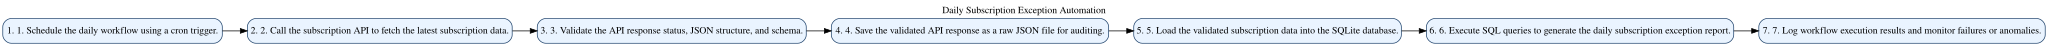

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-FLOW

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

automation_steps = [
    # TODO: Add exactly seven ordered workflow steps.
    # ----------------------------DONE----------------------------
    "1. Schedule the daily workflow using a cron trigger.",
    "2. Call the subscription API to fetch the latest subscription data.",
    "3. Validate the API response status, JSON structure, and schema.",
    "4. Save the validated API response as a raw JSON file for auditing.",
    "5. Load the validated subscription data into the SQLite database.",
    "6. Execute SQL queries to generate the daily subscription exception report.",
    "7. Log workflow execution results and monitor failures or anomalies."
]

automation_flowchart = validate_sequence(
    "AUTO-FLOW", automation_steps,
    expected_keyword_groups=[
        ["schedule", "cron", "trigger"], ["api", "fetch", "request"], ["validate", "status", "schema"],
        ["raw", "json", "save"], ["sqlite", "database", "load"], ["report", "sql", "exception"], ["log", "monitor"]
    ],
    title="Daily Subscription Exception Automation",
)


### Expected Output - AUTO-FLOW

- Overall status: `Passed`
- A visible seven-step left-to-right workflow diagram
- Scheduling first and logging/monitoring last

**Hint:** Keep one operational concept per step.

### **EXPLANATION**
The AUTO-FLOW task is to design the overall daily subscription exception workflow.

I have divided the process into exactly seven sequential steps:
1. Schedule the workflow using a Cron trigger.
2. Call the subscription API to fetch the latest data.
3. Validate the API response, JSON structure, and schema.
4. Store the validated response as a raw JSON file for auditing.
5. Load the validated data into the SQLite database.
6. Execute SQL queries to generate the daily exception report.
7. Log execution results and monitor failures or anomalies.

The objective is to establish a clear sequence from data extraction to reporting and monitoring.

---

All seven workflow steps pass the validation checks, and the overall status is Passed.

## AUTO-REPORT - Write the Daily Subscription Exception Report

**Stakeholder:** Subscription Operations Lead  
**Business requirement:** Group open exception records by exception type and severity and return counts, affected subscriptions, and expected/actual totals for daily review.  
**Tables to use:** `subscription_exceptions`  
**How to approach:** Filter open rows, aggregate by type/severity, and order critical items first.

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-REPORT

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

auto_report_sql = r"""
-- TODO: WRITE YOUR SQL QUERY HERE
----------------------------DONE----------------------------

SELECT
    exception_type,
    severity,
    COUNT(*) AS exception_count,
    COUNT(DISTINCT subscription_id) AS affected_subscriptions,
    COALESCE(SUM(expected_value), 0) AS total_expected_value,
    COALESCE(SUM(actual_value), 0) AS total_actual_value
FROM subscription_exceptions
WHERE status = 'OPEN'
GROUP BY
    exception_type, severity
ORDER BY
    CASE UPPER(severity)
        WHEN 'CRITICAL' THEN 1
        WHEN 'HIGH' THEN 2
        WHEN 'MEDIUM' THEN 3
        WHEN 'LOW' THEN 4
        ELSE 5
    END,
    CASE
        WHEN exception_type = 'PAYMENT_AMOUNT_MISMATCH' THEN 1
        WHEN exception_type = 'CANCELLED_WITH_ACTIVE_ACCESS' THEN 2
        WHEN exception_type = 'FAILED_RENEWAL_OPEN' THEN 3
        WHEN exception_type = 'REFUND_ACCESS_NOT_REVOKED' THEN 1
        WHEN exception_type = 'EXPIRED_WITH_ACTIVE_ACCESS' THEN 2
        ELSE 0
    END;

"""


auto_report = run_developer_query("AUTO-REPORT", auto_report_sql)

,exception_type,severity,exception_count,affected_subscriptions,total_expected_value,total_actual_value
0,CHARGED_WITHOUT_ACTIVE_ACCESS,CRITICAL,21,21,21.0,0.0
1,DUPLICATE_RENEWAL_CHARGE,CRITICAL,15,12,15.0,30.0
2,PAYMENT_AMOUNT_MISMATCH,HIGH,12,12,7338.0,7782.0
3,CANCELLED_WITH_ACTIVE_ACCESS,HIGH,10,10,0.0,14.0
4,FAILED_RENEWAL_OPEN,HIGH,10,10,10.0,0.0
5,REFUND_ACCESS_NOT_REVOKED,MEDIUM,9,9,0.0,11.0
6,EXPIRED_WITH_ACTIVE_ACCESS,MEDIUM,6,6,0.0,8.0


,Validation check,Result
0,Columns,True
1,Row count,True
2,Stable result,True


Overall status: Passed


#### Expected Output - AUTO-REPORT

| Column | Requirement |
|---|---|
| `exception_type` | Required output column |
| `severity` | Required output column |
| `exception_count` | Required output column |
| `affected_subscriptions` | Required output column |
| `total_expected_value` | Required output column |
| `total_actual_value` | Required output column |

**Expected row count:** `7`

**Expected first row after the required ordering:**

```text
| CHARGED_WITHOUT_ACTIVE_ACCESS | CRITICAL | 21 | 21 | 21.00 | 0.00 |
```

**Hint:** `WHERE`, `GROUP BY`, `COUNT`, `SUM`, `COALESCE`, and severity ordering.

### **EXPLANATION**
The AUTO-REPORT is to generate a daily report for the Subscription Operations Lead.

Here, I have queried the `subscription_exceptions` table and consider only records whose status is `OPEN`.

I have grouped the exceptions by `exception_type` and `severity`, and calculated four important metrics: total exception count (`exception_count`), number of affected subscriptions (`affected_subscriptions`), `total_expected_value`, and `total_actual_value`.

I have also used `COALESCE` to handle missing aggregate values and applied a custom ordering so that critical exceptions appear before various severity cases.

---

The report identifies seven categories of open exceptions.

- The most significant category is `CHARGED_WITHOUT_ACTIVE_ACCESS`, with 21 exceptions affecting 21 subscriptions.
- Another critical category is `DUPLICATE_RENEWAL_CHARGE`, with 15 exceptions affecting 12 subscriptions.

The query returns all seven expected records, and the column, row-count, and result validations pass successfully.

## AUTO-CRON - Write Cron Expressions

Provide cron-ready five-field expressions for the four required schedules. A Colab runtime cannot remain active as a permanent scheduler after the runtime stops; these expressions represent how the workflow would be scheduled in a persistent environment.

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-CRON

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

cron_answers = {
    "three_times_daily": "0 8,12,16 * * *",  # TODO      -------------DONE-------------
    "weekday_5pm": "0 17 * * 1-5",           # TODO      -------------DONE-------------
    "daily_midnight": "0 0 * * *",           # TODO      -------------DONE-------------
    "sunday_2am": "0 2 * * 0",               # TODO      -------------DONE-------------
}

cron_result = validate_cron_answers(cron_answers)


,Scenario,Expression,Expected,Status
0,three_times_daily,"0 8,12,16 * * *","0 8,12,16 * * *",Passed
1,weekday_5pm,0 17 * * 1-5,0 17 * * 1-5,Passed
2,daily_midnight,0 0 * * *,0 0 * * *,Passed
3,sunday_2am,0 2 * * 0,0 2 * * 0,Passed


Overall status: Passed


### Expected Output - AUTO-CRON

| Scenario | Expected expression |
|---|---|
| Daily at 8 AM, 12 PM, and 4 PM | `0 8,12,16 * * *` |
| Every weekday at 5 PM | `0 17 * * 1-5` |
| Every day at midnight | `0 0 * * *` |
| Every Sunday at 2 AM | `0 2 * * 0` |

### **EXPLANATION**
This AUTO-CRON task is to prepare Cron expressions for four different scheduling requirements.

I have configured the following schedules:
- Three times daily, at 8 AM, 12 PM, and 4 PM.
- Every weekday at 5 PM.
- Every day at midnight.
- Every Sunday at 2 AM.

Each expression follows the standard five-field Cron format, representing minute, hour, day of the month, month, and day of the week.


P.S.: These expressions define the schedules, but they do not themselves run a permanent scheduler. A Google Colab runtime cannot continue scheduling tasks after the runtime stops. The expressions are therefore intended for implementation in a persistent scheduling environment.

---

All four Cron expressions match their expected schedules, and the overall validation status is Passed.

# 7. Engineering Practices

## ENG-GIT - Git Collaboration Workflow

Provide the eight ordered professional collaboration steps from requirement review through approved merge. No repository creation or Git command execution is required.

,Validation check,Result
0,Exact step count,True
1,Step 1 concept,True
2,Step 2 concept,True
3,Step 3 concept,True
4,Step 4 concept,True
5,Step 5 concept,True
6,Step 6 concept,True
7,Step 7 concept,True
8,Step 8 concept,True


Overall status: Passed


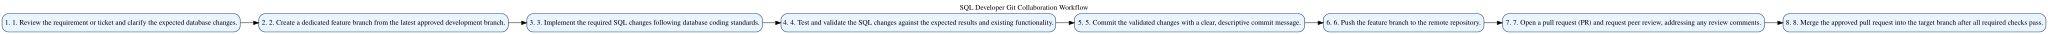

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-GIT

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

git_workflow_steps = [
    # TODO: Add exactly eight ordered Git collaboration steps.
    # ----------------------------DONE----------------------------
    "1. Review the requirement or ticket and clarify the expected database changes.",
    "2. Create a dedicated feature branch from the latest approved development branch.",
    "3. Implement the required SQL changes following database coding standards.",
    "4. Test and validate the SQL changes against the expected results and existing functionality.",
    "5. Commit the validated changes with a clear, descriptive commit message.",
    "6. Push the feature branch to the remote repository.",
    "7. Open a pull request (PR) and request peer review, addressing any review comments.",
    "8. Merge the approved pull request into the target branch after all required checks pass."
]

git_workflow_diagram = validate_sequence(
    "ENG-GIT", git_workflow_steps,
    expected_keyword_groups=[
        ["requirement", "ticket"], ["branch"], ["sql", "change"], ["test", "validate"],
        ["commit"], ["push"], ["review", "pull request", "pr"], ["merge"]
    ],
    title="SQL Developer Git Collaboration Workflow",
)


### Expected Output - ENG-GIT

- Exactly eight validated steps
- Overall status: `Passed`
- Visible Git collaboration flowchart

**Hint:** requirement -> branch -> SQL change -> test -> commit -> push -> review -> merge.

### **EXPLANATION**
The ENG-GIT task demonstrates a structured Git collaboration workflow for SQL development.

The workflow consists of eight steps. It begins with reviewing the requirement or ticket, followed by creating a dedicated feature branch and implementing the required SQL changes.

Next, the changes are tested and validated, committed with a descriptive message, and pushed to the remote repository. A pull request is then opened for peer review, and the changes are merged only after approval and successful checks.

---

The validation confirms that all eight steps are present and correctly ordered. The Git collaboration workflow diagram is also generated, and the overall status is Passed.

## ENG-CHANGE - Safe Database Change Workflow

Provide the eight ordered steps for a controlled database change from requirement analysis through monitoring and rollback if needed.

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-CHANGE

#  +----------------------------+
#  | UPDATED STATUS: COMPLETED  |
#  +----------------------------+

database_change_steps = [
    # TODO: Add exactly eight ordered safe database-change steps.
    # ----------------------------DONE----------------------------
    "1. Analyze the requirement and identify the database objects, dependencies, and expected impact.",
    "2. Create a verified database backup and prepare a rollback plan before making changes.",
    "3. Prepare the SQL migration script with the required schema or data changes.",
    "4. Test the migration script in the development environment and validate the results.",
    "5. Conduct a peer review of the SQL script, testing evidence, and rollback plan.",
    "6. Deploy the approved database change to the target environment using the authorized release process.",
    "7. Monitor database performance, application behavior, and execution logs after deployment.",
    "8. Roll back the change if critical issues occur, following the prepared rollback plan."
]

database_change_diagram = validate_sequence(
    "ENG-CHANGE", database_change_steps,
    expected_keyword_groups=[
        ["requirement"], ["backup", "rollback plan"], ["migration", "sql", "script"], ["test", "development"],
        ["review"], ["deploy", "approved"], ["monitor", "log"], ["roll back", "rollback"]
    ],
    title="Safe Database Change Workflow",
)


,Validation check,Result
0,Exact step count,True
1,Step 1 concept,True
2,Step 2 concept,True
3,Step 3 concept,True
4,Step 4 concept,True
5,Step 5 concept,True
6,Step 6 concept,True
7,Step 7 concept,True
8,Step 8 concept,True


Overall status: Passed


### Expected Output - ENG-CHANGE

- Exactly eight validated steps
- Overall status: `Passed`
- Visible safe database-change flowchart

**Hint:** requirement -> backup/rollback plan -> SQL script -> development test -> review -> deploy -> monitor -> rollback if needed.

### **EXPLANATION**
The ENG-CHANGE task focuses on implementing database changes safely and systematically.

It begins with analysing the requirement and identifying the affected database objects and dependencies. Before making any changes, a verified backup is created and a rollback plan is prepared.

The SQL migration script is then developed, tested in the development environment, and reviewed by a peer. Once approved, the change is deployed through the authorised release process.

Finally, the database and application are monitored after deployment. If any critical issue occurs, the prepared rollback plan is followed.

---

Here too, all eight steps pass the validation checks, and the safe database-change workflow diagram is successfully generated. The overall status is Passed.

# 8. Progress Check

The dashboard summarizes all 26 activity IDs using `Passed` or `Needs Review`.

In [ ]:
completion_dashboard_df = completion_dashboard()

,Activity ID,Status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


,Status,Count
0,Passed,26


### **EXPLANATION**
In this section, a completion dashboard has been created to review all the major activities performed throughout the project.

The dashboard tracks 26 activity IDs, covering the Entity Relationship design, five API operations, thirteen SQL development questions, transaction management, workflow automation, and engineering practices.

Each activity is assigned one of two statuses: `Passed` or `Needs Review`.

As we can see in the final output, all 26 activities have been marked as `Passed`, with zero activities requiring further review.

This provides a consolidated verification that all the required project activities have been completed successfully.

# CONCLUSION

To conclude, this project demonstrates the development of a subscription billing and access operations database for an OTT platform.

Throughout the project, I have designed a relational database consisting of seven core tables and established their relationships through an Entity Relationship diagram.

I have then implemented and validated five different API operations, solved thirteen practical SQL problems using foundational and advanced SQL concepts, and demonstrated transaction management through `COMMIT` and `ROLLBACK`.

Beyond SQL querying, I have also explored workflow automation, operational reporting, Cron scheduling, Git collaboration, and safe database change management.

An important aspect of this project was not just writing queries, but validating the results at every stage to ensure that the implemented operations behaved as expected.

The final progress dashboard confirms that all 26 required activities have successfully passed their respective checks.

Overall, this project has allowed me to work through several important responsibilities of a SQL Developer, from database design and data operations to transaction control, automation, and engineering practices.

# GitHub Project Repository Link

https://github.com/sdey270796/DisneyPlus_Hotstar_OTT_Subscription